# Predicting Diabetes Status Using Health Indicators: A Comparison of Machine Learning and Deep Learning

**Student name:** MILDRED EWENRIM EBOMAH

**Course:** Introduction to Machine Learning

**Submission date:** 16th October, 2026

**GitHub:** https://github.com/MEE-DRED/Diabetes_Health_Indicators_Classification.git   
**Google Drive:** https://drive.google.com/drive/folders/1qVu8UPkFtYcAQ5IzjQ7eqBuDwZKQv2xf?usp=sharing   


---

## 1. Introduction

### Background and motivation

Diabetes is an important public health concern, and identifying patterns associated with it can help us better understand the information available in population health data. For this project, I chose to work with the Diabetes Health Indicators Dataset from Kaggle, which contains health and lifestyle information collected through the U.S. Behavioral Risk Factor Surveillance System (BRFSS).

I wanted to explore whether the available health indicators could help distinguish respondents who report having diabetes from those who do not. I also wanted to compare traditional machine learning models with a neural network to see how well each approach handles this classification problem.

### Problem statement

How effectively can health and lifestyle indicators be used to classify self-reported diabetes status, and how does the performance of traditional machine learning models compare with that of a feed-forward neural network?

### Aim and objectives

The aim of this project is to develop and evaluate classification models for diabetes status using the selected health indicators dataset.

The specific objectives are to:

1. Examine the dataset to understand its structure, quality, and target variable.
2. Clean and preprocess the data while avoiding information leakage between the training, validation, and test sets.
3. Train and compare a majority-class baseline, Logistic Regression, Random Forest, and gradient boosting models.
4. Develop a feed-forward neural network using TensorFlow/Keras.
5. Investigate how hyperparameter tuning, class weighting, feature selection, and regularisation affect model performance.
6. Evaluate the selected models using appropriate metrics and examine the errors they make.
7. Discuss the limitations of the dataset and what the results mean for a health-related classification problem.

### Research questions

This project addresses the following questions:

- Which traditional machine learning model performs best on the validation data?
- Can a feed-forward neural network achieve performance comparable to the traditional models?
- What changes occur when model settings, class weights, and the number of features are adjusted?
- What can the models' false positives and false negatives tell us about their limitations?
- How might the dataset and its features affect the reliability of the results?

### Scope of the project

This project focuses on classifying diabetes status using information already available in the dataset. It is a machine learning study, not a clinical diagnostic exercise. The models learn patterns in the recorded data, but those patterns do not establish that a particular health indicator causes diabetes. The results also depend on how diabetes status was collected and how the target variable was defined.

## 2. Dataset and Environment

### Dataset source

The dataset used in this project is the [Diabetes Health Indicators Dataset on Kaggle](https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset). It is derived from the 2015 U.S. Centers for Disease Control and Prevention Behavioral Risk Factor Surveillance System (BRFSS).

The dataset contains information about respondents' health conditions, lifestyle and demographic characteristics. These variables support an investigation of patterns associated with reported diabetes status.

Several versions are available, including a binary dataset, a balanced subset and a version with three diabetes-status categories. The main experiments use the full binary dataset to preserve the original class distribution rather than evaluating the models on a deliberately balanced subset. The loading section checks the available files before selecting the dataset.

### Environment setup

The following code imports the libraries required for data inspection, preprocessing, model training, evaluation and experiment tracking. It also records software versions and available hardware to support reproducibility.

In [1]:
!pip -q install wandb

In [2]:
import os, sys, json, time, random, platform, warnings, hashlib, importlib.metadata as md_
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED); np.random.seed(SEED)

import sklearn, joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve, ConfusionMatrixDisplay)
from scipy.stats import loguniform, randint, uniform

try:
    import tensorflow as tf
    from tensorflow import keras
    tf.keras.utils.set_random_seed(SEED)
    HAVE_TF = True
except Exception as e:                      # keeps the traditional-ML part usable if TF is missing
    HAVE_TF = False; print("TensorFlow unavailable:", e)

os.environ["WANDB_MODE"] = "offline"        # offline mode: no API key, nothing is uploaded
os.environ["WANDB_SILENT"] = "true"
try:
    import wandb; HAVE_WANDB = True
except Exception as e:
    HAVE_WANDB = False; print("wandb unavailable, falling back to JSONL logging only:", e)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 12, "axes.labelsize": 11})

OUT = Path("outputs"); FIG = OUT/"figures"; MODELS = OUT/"models"; LOGS = OUT/"logs"; RES = OUT/"results"
for p in (FIG, MODELS, LOGS, RES): p.mkdir(parents=True, exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG/f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

def pkg_version(n):
    try: return md_.version(n)
    except Exception: return "not installed"

ENV = {"python": sys.version.split()[0], "platform": platform.platform(), "cpu_count": os.cpu_count(), "seed": SEED,
       **{p: pkg_version(p) for p in ["pandas","numpy","scikit-learn","scipy","tensorflow","keras","matplotlib","seaborn","wandb","joblib"]}}
if HAVE_TF:
    ENV["gpus"] = [g.name for g in tf.config.list_physical_devices("GPU")]
display(pd.Series(ENV, name="value").to_frame())

# --- run configuration ---------------------------------------------------------------------------
DEBUG_SUBSAMPLE = None   # leave None for the real run. An int (e.g. 30000) subsamples AFTER the raw-size check, for dry runs only.
TUNE_SUBSAMPLE  = 50_000 # stratified training subset used ONLY for hyper-parameter search / learning curves (speed)
N_SEARCH_ITER   = 12

,value
python,3.13.15
platform,Linux-6.6.122+-x86_64-with-glibc2.39
cpu_count,2
seed,42
pandas,2.2.3
numpy,2.1.3
scikit-learn,1.6.1
scipy,1.16.3
tensorflow,2.21.0
keras,3.13.2


### Reproducibility

The main libraries use a fixed random seed of `42`, and the experiments share consistent data splits. These choices improve the comparability of the models and make the workflow easier to reproduce.

The notebook also records the environment details and saves the experiment logs and results.

## 3. Loading the Dataset

The dataset is available in multiple versions, and selecting the wrong file could change the target definition or class distribution. The loading step therefore checks the available CSV files and displays their dimensions and target information before modelling begins.

When one suitable full binary dataset is identified, the code can select it automatically. If the available files are ambiguous, execution stops so that the dataset can be selected explicitly. The output from this section identifies the file used, its dimensions and the target variable available for the assignment.

In [3]:
# DATA LOADING: GOOGLE DRIVE
# Dataset folder: My Drive / SUMMATIVE 2026

from pathlib import Path
import pandas as pd

# Configuration
MOUNT_DRIVE = True
DRIVE_FOLDER = Path("/content/drive/MyDrive/SUMMATIVE 2026")
SELECTED_FILE = None  # Set exact CSV filename if multiple candidates exist
TARGET = "Diabetes_binary"
MIN_RAW_ROWS = 20_000

# 1. Mount Google Drive
if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

# 2. Verify that the expected folder exists
if not DRIVE_FOLDER.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DRIVE_FOLDER}\n"
        "Check that SUMMATIVE 2026 is inside My Drive "
        "and that Google Drive has been mounted."
    )

print(f"Dataset folder: {DRIVE_FOLDER}")

# 3. Discover CSV files in the folder and its subfolders
csv_files = sorted(
    f for f in DRIVE_FOLDER.rglob("*")
    if f.is_file() and f.suffix.lower() == ".csv"
)

if not csv_files:
    raise FileNotFoundError(
        f"No CSV files were found inside {DRIVE_FOLDER} "
        "or its subfolders. Check that the dataset is saved "
        "in Google Drive."
    )

# 4. Inspect CSV headers and identify dataset candidates
inventory = []

for path in csv_files:
    try:
        columns = pd.read_csv(path, nrows=0).columns.tolist()
        filename = path.name.lower()

        is_balanced = "5050" in filename
        has_binary_target = TARGET in columns
        has_three_class_target = "Diabetes_012" in columns

        if has_binary_target and not is_balanced:
            kind = "Full binary candidate"
        elif has_binary_target and is_balanced:
            kind = "Balanced binary subset - excluded"
        elif has_three_class_target:
            kind = "Three-class dataset - excluded"
        else:
            kind = "Other CSV - excluded"

        inventory.append({
            "file": path.name,
            "rows": None,
            "columns": len(columns),
            "kind": kind,
            "path": path,
            "columns_list": columns
        })

    except Exception as exc:
        print(f"Could not inspect {path.name}: {exc}")

if not inventory:
    raise ValueError("CSV files were found, but none could be inspected.")

# Show what was discovered
display(pd.DataFrame([
    {
        "file": item["file"],
        "columns": item["columns"],
        "kind": item["kind"]
    }
    for item in inventory
]))

# 5. Select the full binary dataset
if SELECTED_FILE is not None:
    selected = [
        item for item in inventory
        if item["file"] == SELECTED_FILE
    ]

    if len(selected) != 1:
        raise FileNotFoundError(
            f"Could not uniquely find SELECTED_FILE={SELECTED_FILE!r}. "
            f"Available CSVs: {[item['file'] for item in inventory]}"
        )

    chosen = selected[0]

    if TARGET not in chosen["columns_list"]:
        raise ValueError(
            f"{SELECTED_FILE} does not contain the target column {TARGET!r}."
        )

    if "5050" in chosen["file"].lower():
        raise ValueError(
            "The selected file appears to be the balanced 50/50 subset. "
            "Choose the full binary dataset instead."
        )

else:
    candidates = [
        item for item in inventory
        if item["kind"] == "Full binary candidate"
    ]

    if len(candidates) == 0:
        raise ValueError(
            f"No suitable full binary dataset containing {TARGET!r} "
            "was found. Check the CSV file and its column names."
        )

    if len(candidates) > 1:
        raise ValueError(
            "Multiple full binary dataset candidates were found: "
            f"{[item['file'] for item in candidates]}. "
            "Set SELECTED_FILE to the exact filename at the top "
            "of this cell, then rerun."
        )

    chosen = candidates[0]

DATA_PATH = chosen["path"]

print(f"\nSelected dataset: {DATA_PATH.name}")
print(f"Dataset location: {DATA_PATH}")

# 6. Load the dataset
df_raw = pd.read_csv(DATA_PATH)

N_RAW_ROWS, N_RAW_COLS = df_raw.shape

print(
    f"\nRaw shape before preprocessing: "
    f"{N_RAW_ROWS:,} rows x {N_RAW_COLS} columns"
)

# 7. Validate the dataset
if TARGET not in df_raw.columns:
    raise KeyError(
        f"Target column {TARGET!r} is missing. "
        f"Available columns: {list(df_raw.columns)}"
    )

if N_RAW_ROWS < MIN_RAW_ROWS:
    raise ValueError(
        f"The dataset contains {N_RAW_ROWS:,} rows, fewer than "
        f"the required {MIN_RAW_ROWS:,}. Check that you selected "
        "the full dataset rather than a subset."
    )

print(f"Target column ({TARGET}): FOUND")
print(f"Minimum row requirement (>= {MIN_RAW_ROWS:,}): SATISFIED")
print("Balanced 50/50 subset: NOT selected by filename check")
print("\nDataset loaded successfully.")
display(df_raw.head())


Mounted at /content/drive
Dataset folder: /content/drive/MyDrive/SUMMATIVE 2026


,file,columns,kind
0,diabetes_012_health_indicators_BRFSS2015.csv,22,Three-class dataset - excluded
1,diabetes_binary_5050split_health_indicators_BR...,22,Balanced binary subset - excluded
2,diabetes_binary_health_indicators_BRFSS2015.csv,22,Full binary candidate



Selected dataset: diabetes_binary_health_indicators_BRFSS2015.csv
Dataset location: /content/drive/MyDrive/SUMMATIVE 2026/diabetes_binary_health_indicators_BRFSS2015.csv

Raw shape before preprocessing: 253,680 rows x 22 columns
Target column (Diabetes_binary): FOUND
Minimum row requirement (>= 20,000): SATISFIED
Balanced 50/50 subset: NOT selected by filename check

Dataset loaded successfully.


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


### Checking the Target Variable

The target variable must be understood before the classification models are built because the available dataset versions use different diabetes-status definitions. The label should therefore be interpreted using the data and its documentation, rather than the column name alone.

Where both binary and three-category files are available, the following check compares their labels. This helps establish how the binary target corresponds to the three-category version and whether respondents classified as having prediabetes are included in the negative class.

In [4]:

import os
import pandas as pd

# Find CSV files that contain the original three-class target
three = []

for p in csv_files:
    try:
        if "Diabetes_012" in pd.read_csv(p, nrows=0).columns:
            three.append(p)
    except Exception as e:
        print(f"Could not inspect {p}: {e}")

TARGET_DEFINITION = (
    "unverified (three-class file not supplied) - "
    "rely on Kaggle documentation"
)

if three:
    d012 = pd.read_csv(three[0], usecols=["Diabetes_012"])["Diabetes_012"]

    if len(d012) == N_RAW_ROWS:
        xt = pd.crosstab(
            d012,
            df_raw[TARGET],
            rownames=["Diabetes_012"],
            colnames=[TARGET]
        )
        display(xt)

        if ((d012 == 2).astype(float) == df_raw[TARGET]).all():
            TARGET_DEFINITION = (
                "1 = respondent reported diabetes "
                "(Diabetes_012 == 2); "
                "0 = no diabetes OR prediabetes "
                "(Diabetes_012 in {0,1})"
            )

        elif ((d012 > 0).astype(float) == df_raw[TARGET]).all():
            TARGET_DEFINITION = (
                "1 = diabetes OR prediabetes "
                "(Diabetes_012 in {1,2}); "
                "0 = no diabetes"
            )

        else:
            TARGET_DEFINITION = (
                "does not match either simple recoding "
                "of Diabetes_012 - inspect manually"
            )
    else:
        print(
            f"Row count mismatch: found {len(d012):,} rows; "
            f"expected {N_RAW_ROWS:,}."
        )
else:
    print("No CSV containing Diabetes_012 was found.")

print("VERIFIED TARGET DEFINITION:", TARGET_DEFINITION)


Diabetes_binary,0.0,1.0
Diabetes_012,,
0.0,213703,0
1.0,4631,0
2.0,0,35346


VERIFIED TARGET DEFINITION: 1 = respondent reported diabetes (Diabetes_012 == 2); 0 = no diabetes OR prediabetes (Diabetes_012 in {0,1})


### What the Target Variable Represents

The cross-tabulation above shows how the binary target corresponds to the three-category version of the dataset. In particular, it indicates whether respondents reporting prediabetes are grouped with respondents who do not report diabetes.

This distinction affects the interpretation of model errors. If prediabetes is included in class 0, that class does not represent only respondents with no related metabolic condition. Some respondents in the negative class may have reported prediabetes.

The target is therefore described as **reported diabetes status**, not as a confirmed clinical diagnosis.

## 4. Initial Data Audit

The initial audit examines the dataset's dimensions, data types, missing values, duplicate records, target distribution and feature ranges. These checks help establish the dataset's quality before cleaning and modelling.

The audit also checks whether feature values fall within the expected ranges of the BRFSS survey variables. A dataset can contain no missing values and still include values that require investigation.

The results guide the preprocessing decisions.

In [5]:
print("Columns:", list(df_raw.columns))
display(df_raw.head())
display(pd.DataFrame({"dtype": df_raw.dtypes.astype(str), "n_unique": df_raw.nunique(), "n_missing": df_raw.isna().sum()}))

n_dup = int(df_raw.duplicated().sum())
print(f"\nExact duplicate rows: {n_dup:,} ({n_dup/N_RAW_ROWS:.2%})")
print("Total missing cells:", int(df_raw.isna().sum().sum()))

cls = df_raw[TARGET].value_counts().sort_index()
cls_tbl = pd.DataFrame({"count": cls, "percent": (cls/cls.sum()*100).round(3)}); display(cls_tbl)
print("Imbalance ratio (majority:minority) = %.2f : 1" % (cls.max()/cls.min()))

display(df_raw.describe().T)

FEATURES = [c for c in df_raw.columns if c != TARGET]
EXPECTED = {"GenHlth": (1,5), "MentHlth": (0,30), "PhysHlth": (0,30), "Age": (1,13), "Education": (1,6), "Income": (1,8), "BMI": (12,98)}
BINARY = [c for c in FEATURES if set(df_raw[c].dropna().unique()) <= {0, 1}]
NUMERIC = [c for c in FEATURES if c not in BINARY]
invalid = {}
for c in FEATURES:
    lo, hi = EXPECTED.get(c, (0, 1))
    bad = int(((df_raw[c] < lo) | (df_raw[c] > hi)).sum())
    if bad: invalid[c] = bad
print("\nBinary indicators (%d): %s" % (len(BINARY), BINARY))
print("Numeric / ordinal (%d): %s" % (len(NUMERIC), NUMERIC))
print("Out-of-range values by column:", invalid or "none")
near_const = {c: float(df_raw[c].value_counts(normalize=True).iloc[0]) for c in FEATURES if df_raw[c].value_counts(normalize=True).iloc[0] > 0.95}
print("Constant / near-constant (>95% one value):", {k: round(v, 3) for k, v in near_const.items()} or "none")

Columns: ['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


,dtype,n_unique,n_missing
Diabetes_binary,float64,2,0
HighBP,float64,2,0
HighChol,float64,2,0
CholCheck,float64,2,0
BMI,float64,84,0
Smoker,float64,2,0
Stroke,float64,2,0
HeartDiseaseorAttack,float64,2,0
PhysActivity,float64,2,0
Fruits,float64,2,0



Exact duplicate rows: 24,206 (9.54%)
Total missing cells: 0


,count,percent
Diabetes_binary,,
0.0,218334,86.067
1.0,35346,13.933


Imbalance ratio (majority:minority) = 6.18 : 1


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0



Binary indicators (14): ['HighBP', 'HighChol', 'CholCheck', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'DiffWalk', 'Sex']
Numeric / ordinal (7): ['BMI', 'GenHlth', 'MentHlth', 'PhysHlth', 'Age', 'Education', 'Income']
Out-of-range values by column: none
Constant / near-constant (>95% one value): {'CholCheck': 0.963, 'Stroke': 0.959, 'AnyHealthcare': 0.951}


In [6]:
# ---- eligibility summary
y_vals = sorted(int(v) for v in df_raw[TARGET].dropna().unique())
checks = {
    f"Raw rows >= {MIN_RAW_ROWS:,}  (actual {N_RAW_ROWS:,})": N_RAW_ROWS >= MIN_RAW_ROWS,
    f"Target '{TARGET}' present": TARGET in df_raw.columns,
    f"Target categorical with >= 2 classes (found {y_vals})": len(y_vals) >= 2 and set(y_vals) <= {0, 1},
    "Target has no missing values": df_raw[TARGET].isna().sum() == 0,
    "Not a balanced/resampled subset": "5050" not in DATA_PATH.name,
}
print("DATASET ELIGIBILITY SUMMARY"); print("-"*60)
for k, v in checks.items(): print(("PASS  " if v else "FAIL  ") + k)
assert all(checks.values()), "Dataset eligibility failed - see summary above."

DATASET ELIGIBILITY SUMMARY
------------------------------------------------------------
PASS  Raw rows >= 20,000  (actual 253,680)
PASS  Target 'Diabetes_binary' present
PASS  Target categorical with >= 2 classes (found [0, 1])
PASS  Target has no missing values
PASS  Not a balanced/resampled subset


### What the Data Audit Shows

The dataset contains 253,680 rows and 22 columns: one target variable and 21 features.

The target distribution is imbalanced. Class 0 contains 218,334 respondents (86.07%), while class 1 contains 35,346 respondents (13.93%), giving a majority-to-minority ratio of approximately 6.18:1. A model that predicts class 0 for every respondent could achieve high accuracy while failing to identify any positive cases. Model comparisons therefore consider PR-AUC, recall, precision and F1-score alongside accuracy.

The dataset contains no missing cells, and the range checks found no out-of-range values. However, 24,206 rows (9.54%) are exact duplicate rows. Their effect on class distribution and evaluation is examined before the modelling decisions are finalised.

Three features—`CholCheck`, `Stroke` and `AnyHealthcare`—have more than 95% of their values concentrated in one category.

## 5. Exploratory Data Analysis

Exploratory data analysis examines the distribution of diabetes status, the distributions of individual features and the proportion of respondents in class 1 across selected health and lifestyle indicators. A correlation heatmap is also used to identify features that tend to vary together.

The interquartile range (IQR) method flags unusually high or low values in selected numerical features. These flags support further inspection but do not, by themselves, establish that a value is wrong.

The analysis describes patterns in cross-sectional survey data. An association between a feature and reported diabetes status does not establish that the feature caused diabetes.

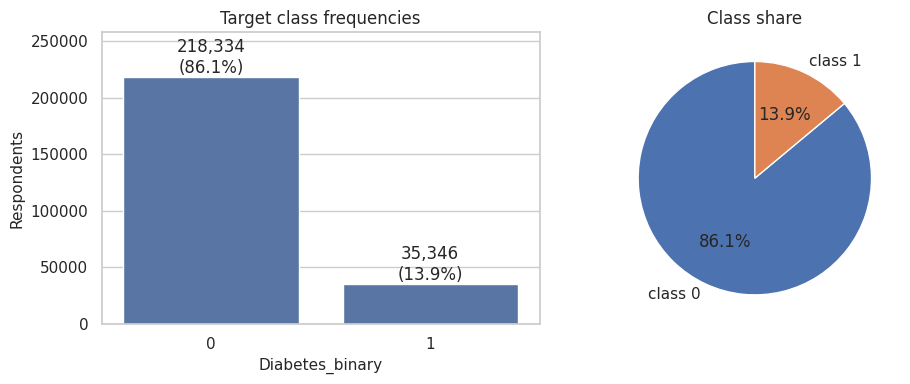

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x=cls.index.astype(int).astype(str), y=cls.values, ax=ax[0], color="#4C72B0")
for i, v in enumerate(cls.values): ax[0].text(i, v, f"{v:,}\n({v/cls.sum():.1%})", ha="center", va="bottom")
ax[0].set(title="Target class frequencies", xlabel=TARGET, ylabel="Respondents"); ax[0].set_ylim(0, cls.max()*1.18)
ax[1].pie(cls.values, labels=[f"class {int(i)}" for i in cls.index], autopct="%1.1f%%", colors=["#4C72B0", "#DD8452"], startangle=90)
ax[1].set_title("Class share"); savefig("eda_target_distribution")

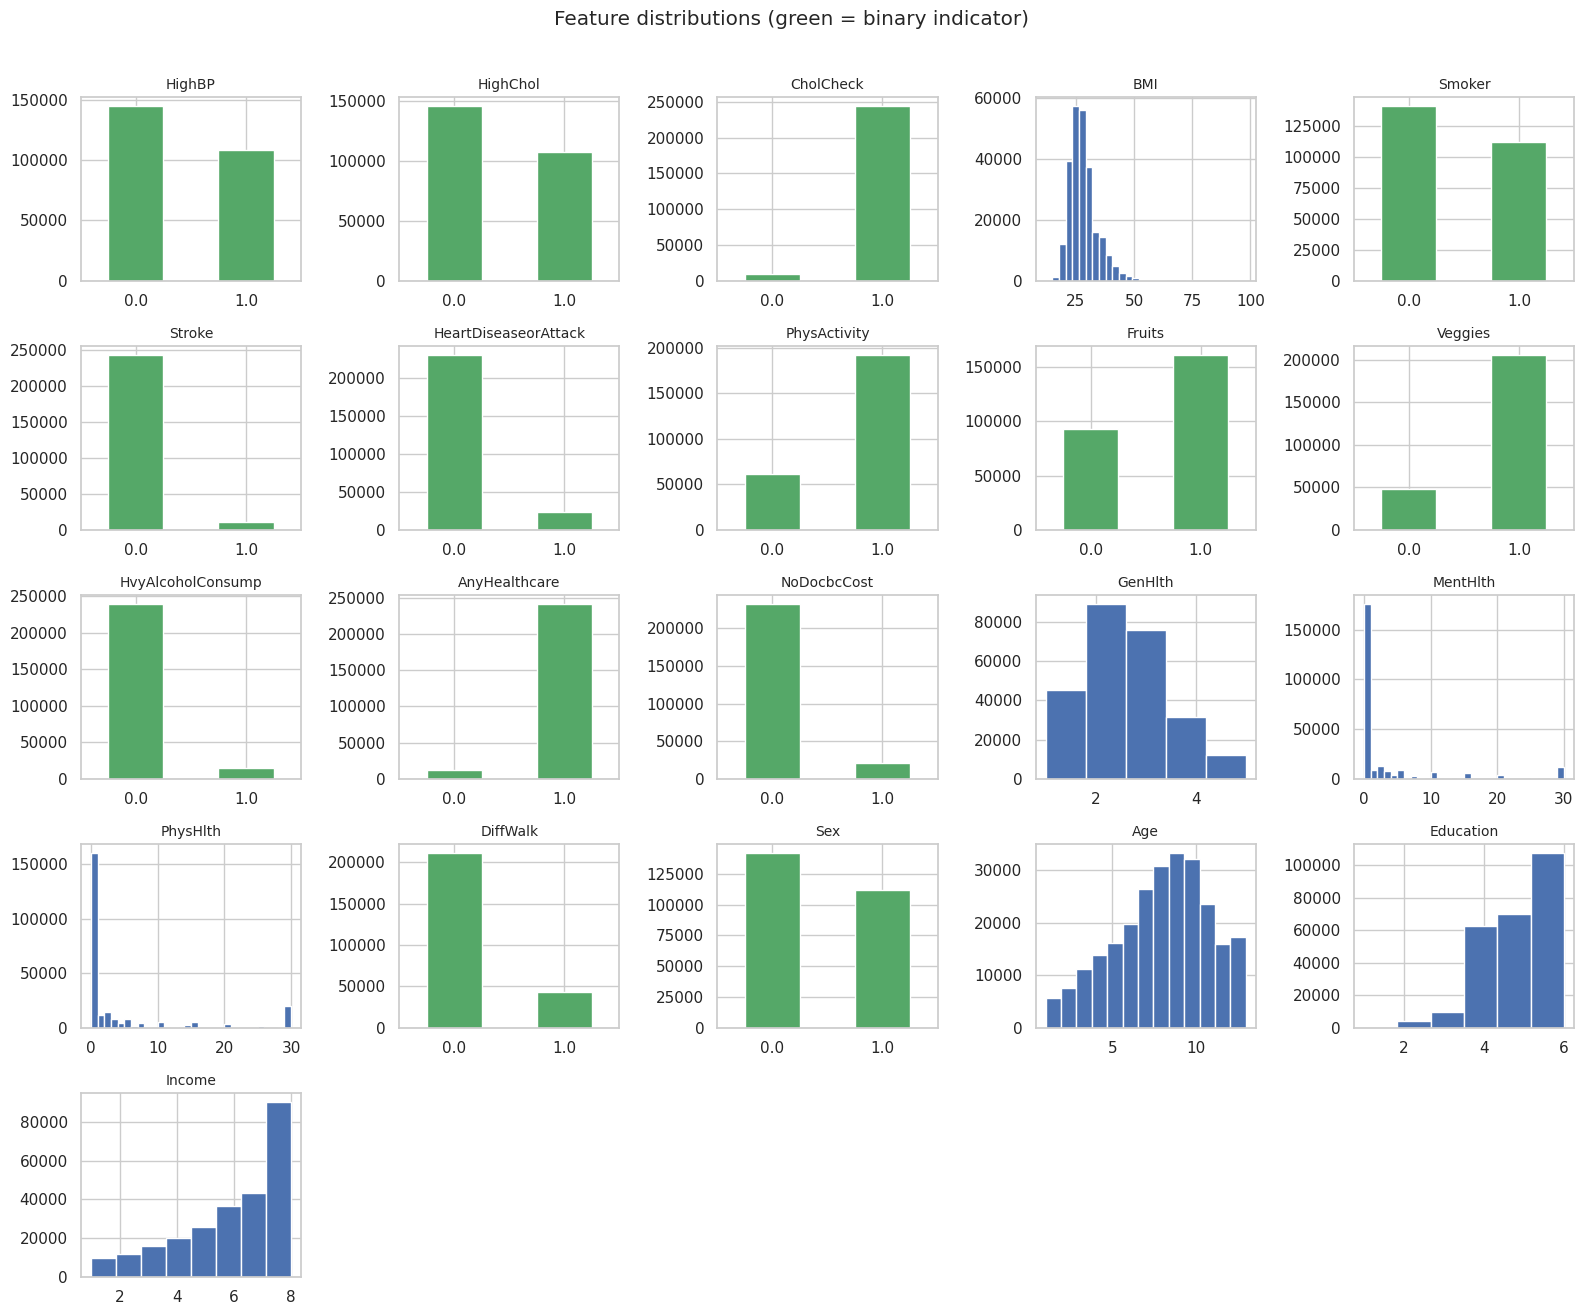

In [8]:
ncols = 5; nrows = int(np.ceil(len(FEATURES)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.2*ncols, 2.6*nrows)); axes = axes.ravel()
for a, c in zip(axes, FEATURES):
    if c in BINARY: df_raw[c].value_counts().sort_index().plot.bar(ax=a, color="#55A868", rot=0)
    else: a.hist(df_raw[c], bins=min(30, df_raw[c].nunique()), color="#4C72B0")
    a.set_title(c, fontsize=10); a.set_xlabel(""); a.set_ylabel("")
for a in axes[len(FEATURES):]: a.axis("off")
plt.suptitle("Feature distributions (green = binary indicator)", y=1.01); savefig("eda_feature_distributions")

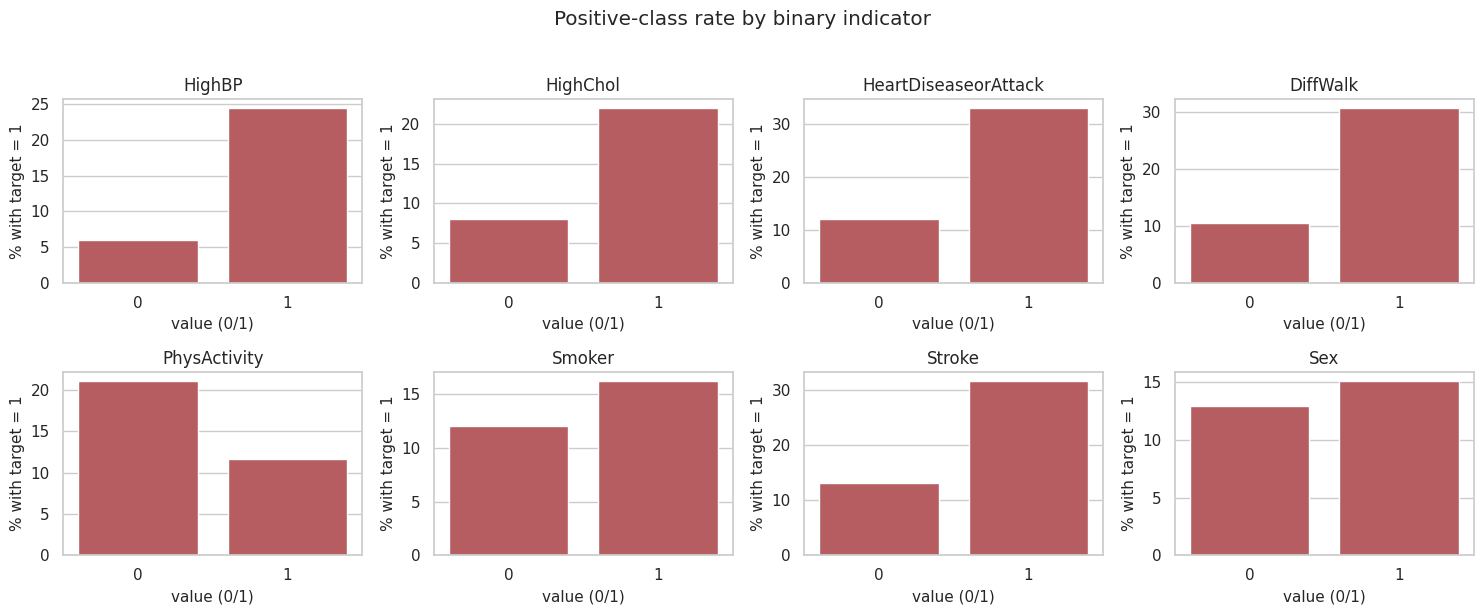

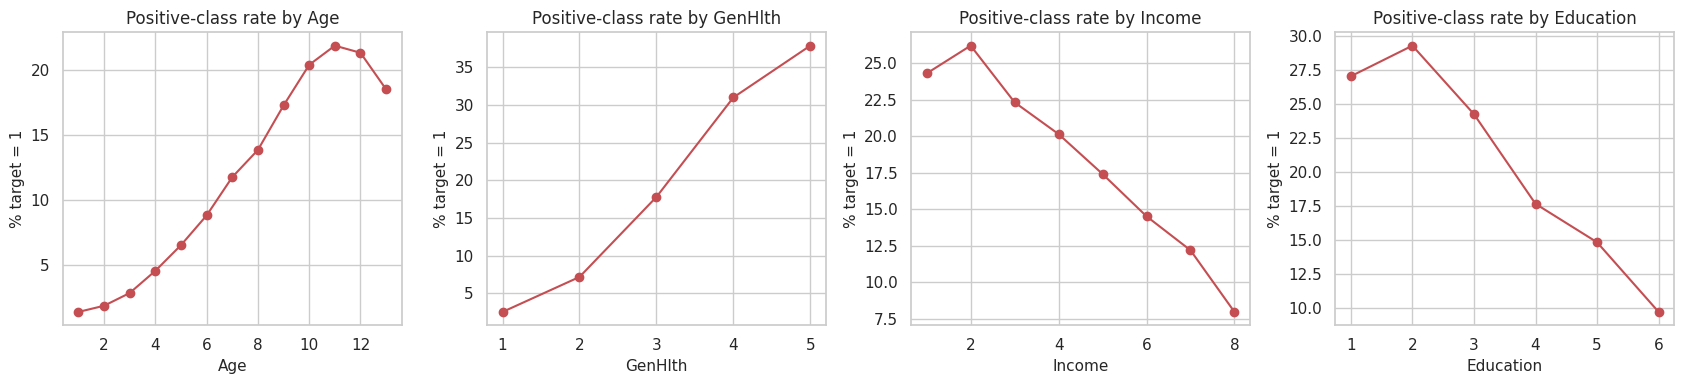

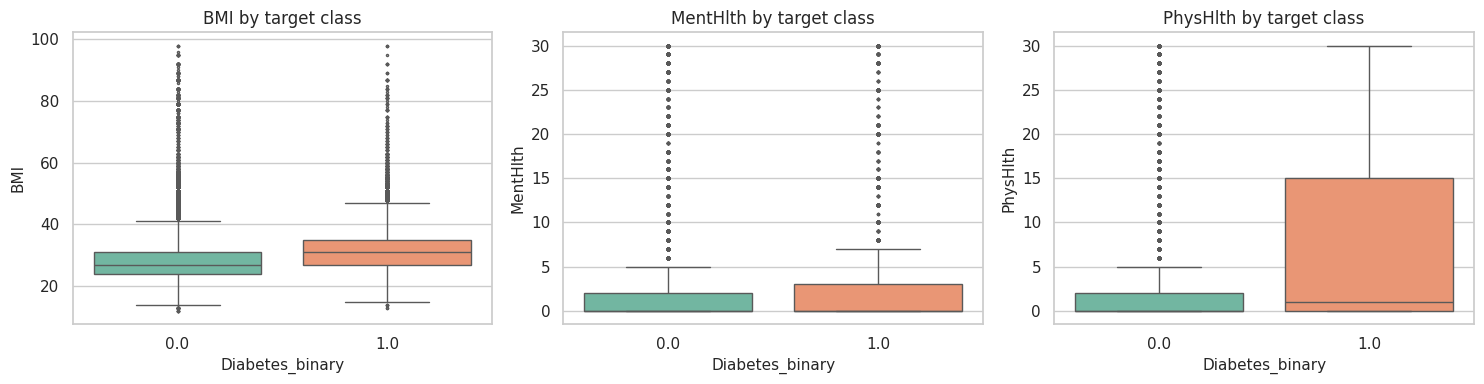

In [9]:
# Positive-class rate by feature value: association, NOT causation
focus_bin = ["HighBP", "HighChol", "HeartDiseaseorAttack", "DiffWalk", "PhysActivity", "Smoker", "Stroke", "Sex"]
fig, axes = plt.subplots(2, 4, figsize=(15, 6)); axes = axes.ravel()
for a, c in zip(axes, focus_bin):
    r = df_raw.groupby(c)[TARGET].mean()*100
    sns.barplot(x=r.index.astype(int).astype(str), y=r.values, ax=a, color="#C44E52")
    a.set(title=c, xlabel="value (0/1)", ylabel="% with target = 1")
plt.suptitle("Positive-class rate by binary indicator", y=1.02); savefig("eda_rate_by_binary")

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for a, c in zip(axes, ["Age", "GenHlth", "Income", "Education"]):
    r = df_raw.groupby(c)[TARGET].mean()*100
    a.plot(r.index, r.values, marker="o", color="#C44E52"); a.set(title=f"Positive-class rate by {c}", xlabel=c, ylabel="% target = 1")
savefig("eda_rate_by_ordinal")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.boxplot(data=df_raw, x=TARGET, y=c, ax=a, hue=TARGET, palette="Set2", legend=False, fliersize=1.5)
    a.set_title(f"{c} by target class")
savefig("eda_boxplots_by_class")

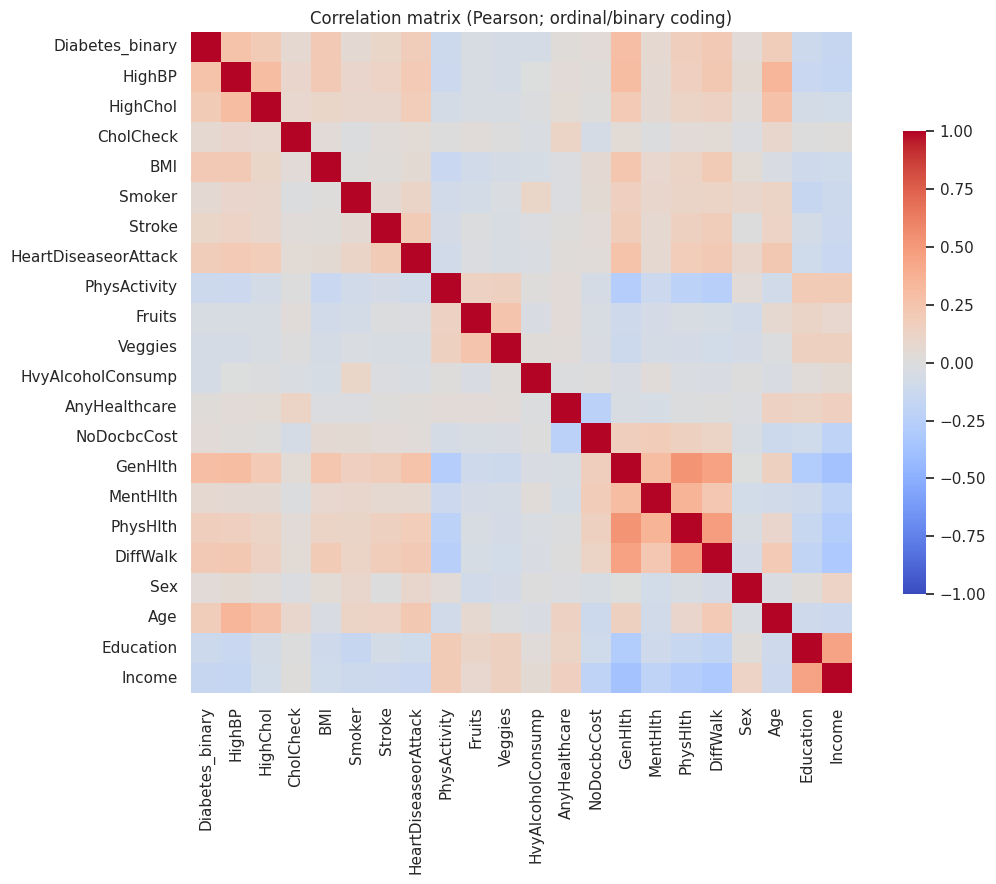

Strongest feature pairs (|r| >= 0.30):


,feature_a,feature_b,r
204,GenHlth,PhysHlth,0.524364
216,PhysHlth,DiffWalk,0.478417
205,GenHlth,DiffWalk,0.456920
230,Education,Income,0.449106
209,GenHlth,Income,-0.370014
210,MentHlth,PhysHlth,0.353619
38,HighBP,Age,0.344452
224,DiffWalk,Income,-0.320124
203,GenHlth,MentHlth,0.301674
33,HighBP,GenHlth,0.300530


Correlation of each feature with the target:


,r_with_target
GenHlth,0.293569
HighBP,0.263129
DiffWalk,0.218344
BMI,0.216843
HighChol,0.200276
Age,0.177442
HeartDiseaseorAttack,0.177282
PhysHlth,0.171337
Income,-0.163919
Education,-0.124456


,feature,lower_fence,upper_fence,n_outside,pct_outside,max
0,BMI,13.5,41.5,9847,3.88,98.0
1,MentHlth,-3.0,5.0,36208,14.27,30.0
2,PhysHlth,-4.5,7.5,40949,16.14,30.0


BMI >= 60: 868 | BMI >= 80: 281


In [10]:
corr = df_raw.corr(numeric_only=True)
plt.figure(figsize=(12, 9)); sns.heatmap(corr, cmap="coolwarm", center=0, vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .7})
plt.title("Correlation matrix (Pearson; ordinal/binary coding)"); savefig("eda_correlation_heatmap")

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().rename("r").reset_index()
pairs.columns = ["feature_a", "feature_b", "r"]
print("Strongest feature pairs (|r| >= 0.30):"); display(pairs[pairs.r.abs() >= 0.30].sort_values("r", key=abs, ascending=False))
print("Correlation of each feature with the target:"); display(corr[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).to_frame("r_with_target"))

# IQR outlier counts for numeric variables
rows = []
for c in ["BMI", "MentHlth", "PhysHlth"]:
    q1, q3 = df_raw[c].quantile([.25, .75]); iqr = q3-q1; lo, hi = q1-1.5*iqr, q3+1.5*iqr
    rows.append({"feature": c, "lower_fence": lo, "upper_fence": hi, "n_outside": int(((df_raw[c] < lo) | (df_raw[c] > hi)).sum()),
                 "pct_outside": round(100*((df_raw[c] < lo) | (df_raw[c] > hi)).mean(), 2), "max": df_raw[c].max()})
display(pd.DataFrame(rows))
print("BMI >= 60:", int((df_raw.BMI >= 60).sum()), "| BMI >= 80:", int((df_raw.BMI >= 80).sum()))

### What the Exploratory Analysis Shows

The target distribution confirms the imbalance identified in the initial audit: class 0 accounts for 86.07% of the dataset and class 1 accounts for 13.93%. This supports evaluating the models on their ability to identify the minority class rather than relying on accuracy alone.

The correlation analysis identifies relationships between some features. The strongest reported pair is `GenHlth` and `PhysHlth` (approximately 0.52), followed by `PhysHlth` and `DiffWalk` (0.48), and `Education` and `Income` (0.45).

`GenHlth` has the strongest positive correlation with the target (approximately 0.29), followed by `HighBP` (0.26), `DiffWalk` (0.22), `BMI` (0.22) and `HighChol` (0.20). `Income` and `Education` have negative correlations of approximately -0.16 and -0.12, respectively. These relationships are modest; no single feature is sufficient to determine reported diabetes status.

The IQR analysis flags values in `BMI`, `MentHlth` and `PhysHlth`. An IQR flag does not necessarily indicate a data error: 30 days of poor physical or mental health is a valid response, and a high BMI may represent a genuine observation. Removing such values without additional evidence could discard useful information.

The modelling experiments therefore retain these features and observations. Numerical and ordinal features are standardised for models that are sensitive to feature scale, while outlier-flagged observations are not removed solely because of the IQR results. The relationships described here are associations in cross-sectional data and may reflect confounding or reverse causation.

## 6. Data Cleaning and Preprocessing

The initial audit found no missing cells and no values outside the expected feature ranges.
| Issue | Decision and rationale |
|---|---|
| Missing values | No missing cells were found in the current dataset. Imputers remain in the preprocessing pipelines to support a consistent workflow if missing values occur in future data. |
| Duplicate rows | Exact duplicates are retained for the main experiments because identical survey responses may come from different respondents. The resulting class-distribution and evaluation limitations are considered explicitly. |
| Outliers | IQR-flagged observations are retained because they may represent valid responses rather than data-entry errors. |
| Binary indicators | These are already coded as 0 and 1, so additional encoding is not required. |
| Numerical and ordinal features | These remain numerical. Standardisation is applied where required by scale-sensitive models. |
| Categorical encoding | The selected features are binary or ordinal-coded, so a separate one-hot encoding step is not used in these experiments. |
| Target leakage | The target remains separate from the input features. Preprocessing and feature selection are fitted using training data only. |

Where applicable, preprocessing is integrated into the modelling pipelines. This prevents transformations from being fitted using information from the validation or test sets.

In [11]:
n_dup = int(df_raw.duplicated().sum())
dup_mask = df_raw.duplicated(keep=False)
print(f"Rows involved in an exact-duplicate group: {int(dup_mask.sum()):,}")
print("Positive rate - all rows: %.4f | duplicated rows: %.4f | de-duplicated data: %.4f" % (
      df_raw[TARGET].mean(), df_raw.loc[dup_mask, TARGET].mean(), df_raw.drop_duplicates()[TARGET].mean()))
conflict = df_raw[dup_mask].groupby(FEATURES)[TARGET].nunique()
print(f"Identical feature vectors carrying *conflicting* labels: {(conflict > 1).sum():,} groups "
      "(evidence of irreducible label noise given these features)")

df = df_raw.copy()
if DEBUG_SUBSAMPLE:
    df = df.groupby(TARGET, group_keys=False).sample(frac=DEBUG_SUBSAMPLE/len(df), random_state=SEED).reset_index(drop=True)
    print(f"!! DEBUG MODE: using {len(df):,} rows. Not valid for reporting. !!")
X = df[FEATURES].copy(); y = df[TARGET].astype(int).copy()
assert TARGET not in X.columns
print("X:", X.shape, "| y:", y.shape)

def make_prep(features, scale):
    # Preprocessing for a given feature subset.
    num = [c for c in features if c in NUMERIC]; binc = [c for c in features if c in BINARY]
    steps = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([("num", Pipeline(steps), num), ("bin", SimpleImputer(strategy="most_frequent"), binc)], remainder="drop")

Rows involved in an exact-duplicate group: 35,575
Positive rate - all rows: 0.1393 | duplicated rows: 0.0135 | de-duplicated data: 0.1529
Identical feature vectors carrying *conflicting* labels: 67 groups (evidence of irreducible label noise given these features)
X: (253680, 21) | y: (253680,)


### Interpretation: Preprocessing and Duplicate Records

The duplicate analysis identifies 35,575 rows involved in exact-duplicate groups out of 253,680 rows. The positive-class rate is approximately 1.35% among these rows, compared with 13.93% across the full dataset. After duplicate rows are removed, the positive-class rate rises to approximately 15.29%.

Removing duplicates would therefore change both the dataset size and the target distribution. Because the features consist largely of binary indicators and small ordinal scales, different respondents can share the same feature combination. The main experiments retain duplicates rather than assuming that every repeated row is an erroneous record.

The analysis also identifies 67 groups in which identical feature combinations have conflicting target labels. This indicates that the available features do not uniquely determine reported diabetes status: respondents with the same recorded indicators can have different labels.

Retaining duplicates has an evaluation limitation. Some validation and test rows have feature combinations that also appear in the training set, potentially making held-out performance more optimistic than performance on genuinely novel feature combinations. The next section quantifies this overlap, and the limitation is considered when interpreting model scores.

## 7. Train, Validation and Test Splits

The dataset is divided into training, validation and test sets using a stratified 70/15/15 split. Stratification maintains approximately the same proportion of each target class in all three sets, which is important given the class imbalance.

The training set is used to fit the models. The validation set supports model comparison, hyperparameter tuning and threshold selection. The test set remains untouched until the final evaluation.

All experiments use the same split and random seed to support fair comparisons. Any cross-validation is restricted to the training data, and preprocessing and feature selection are fitted without using validation or test information.

The output reports the size and class distribution of each subset. It also measures how often exact feature combinations appear in both the training set and the held-out sets, because this overlap affects the interpretation of evaluation results.

In [12]:
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
del X_tmp, y_tmp
SPLIT_DESC = f"stratified 70/15/15 (train {len(X_train):,} / val {len(X_val):,} / test {len(X_test):,}), seed {SEED}"
split_tbl = pd.DataFrame({n: {"rows": len(yy), "class_0": int((yy == 0).sum()), "class_1": int((yy == 1).sum()),
                              "pct_class_1": round(100*yy.mean(), 3)} for n, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]}).T
display(split_tbl); print(SPLIT_DESC)

# Leakage diagnostic using FEATURES ONLY (no labels, nothing is fitted or tuned): how many val/test rows have an identical twin in train?
h = lambda d: pd.util.hash_pandas_object(d, index=False)
train_hashes = set(h(X_train))
TWIN_VAL = float(h(X_val).isin(train_hashes).mean()); TWIN_TEST = float(h(X_test).isin(train_hashes).mean())
print(f"Rows whose exact feature vector also occurs in train -> validation: {TWIN_VAL:.1%}, test: {TWIN_TEST:.1%}")

# Stratified training subset used ONLY for search / learning curves
if len(X_train) > TUNE_SUBSAMPLE:
    X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=TUNE_SUBSAMPLE, stratify=y_train, random_state=SEED)
else:
    X_tune, y_tune = X_train, y_train
print("Tuning subset:", X_tune.shape, "positive rate %.3f" % y_tune.mean())

,rows,class_0,class_1,pct_class_1
train,177576.0,152834.0,24742.0,13.933
validation,38052.0,32750.0,5302.0,13.934
test,38052.0,32750.0,5302.0,13.934


stratified 70/15/15 (train 177,576 / val 38,052 / test 38,052), seed 42
Rows whose exact feature vector also occurs in train -> validation: 12.8%, test: 12.6%
Tuning subset: (50000, 21) positive rate 0.139


### Interpreting the Data Splits

The split contains 177,576 training rows, 38,052 validation rows and 38,052 test rows. The positive-class proportion is approximately 13.93% in each subset, indicating that stratification worked as intended.

Using the same split for each experiment makes comparisons more meaningful because performance differences are less likely to result from evaluating models on different observations.

The preprocessing pipelines also help prevent leakage: transformations such as imputation and standardisation are fitted on the training data and then applied to validation and test data. The validation set informs model selection, while the test set is reserved for the final evaluation.

Approximately 12.8% of validation rows and 12.6% of test rows have an exact feature combination that also appears in the training set. This overlap is possible because the survey features use relatively coarse categories and does not necessarily mean that the same respondent appears more than once. Nevertheless, it may make held-out scores somewhat optimistic compared with performance on a population with different feature combinations.

## 8. Baseline and Traditional Machine Learning

### 8.0 Evaluation and experiment-tracking utilities

This section evaluates how well traditional machine learning models classify reported diabetes status using the 21 available features.

The majority-class baseline always predicts the more common class and ignores the input features. It provides a reference point for assessing whether the learned models identify useful patterns beyond the class distribution alone.

The learned models are Logistic Regression, Random Forest and Histogram Gradient Boosting. Logistic Regression provides a relatively simple linear reference, while the tree-based methods can capture non-linear relationships and interactions between features.

All models use the same training and validation splits. Performance is assessed using accuracy, precision, recall, F1-score, ROC-AUC and PR-AUC. PR-AUC receives particular attention because class 1 is the minority class.

The experiment-tracking utilities record each run's settings, metrics and training time, allowing results to be compared consistently in later sections.

In [13]:
def compute_metrics(y_true, proba, thr=0.5):
    y_true = np.asarray(y_true); proba = np.asarray(proba, dtype=float).ravel(); pred = (proba >= thr).astype(int)
    m = {"accuracy": accuracy_score(y_true, pred), "precision": precision_score(y_true, pred, zero_division=0),
         "recall": recall_score(y_true, pred, zero_division=0), "f1": f1_score(y_true, pred, zero_division=0),
         "roc_auc": np.nan, "pr_auc": np.nan, "threshold": thr}
    if len(np.unique(y_true)) == 2:
        try: m["roc_auc"] = roc_auc_score(y_true, proba); m["pr_auc"] = average_precision_score(y_true, proba)
        except ValueError: pass
    return m

class ExperimentTracker:
    def __init__(self, log_dir, project="diabetes-health-indicators"):
        self.records, self.project, self.log_dir = [], project, Path(log_dir)
        (self.log_dir/"experiment_log.jsonl").unlink(missing_ok=True)
        self.wandb_ok = HAVE_WANDB

    def log(self, exp_id, paradigm, family, model, params, preprocessing, protocol, metrics, runtime_s,
            notes="", ref=None, eval_split="validation", history=None, extra=None):
        rec = {"exp_id": exp_id, "paradigm": paradigm, "family": family, "model": model,
               "hyperparameters": json.dumps(params, default=str, sort_keys=True), "preprocessing": preprocessing,
               "protocol": protocol, "eval_split": eval_split, "seed": SEED, "runtime_s": round(runtime_s, 2),
               **{k: (None if (isinstance(v, float) and np.isnan(v)) else v) for k, v in metrics.items()}, "notes": notes}
        if extra: rec.update(extra)
        prev = {r["exp_id"]: r for r in self.records}
        if ref and ref in prev and prev[ref].get("pr_auc") is not None and rec.get("pr_auc") is not None:
            rec["observation"] = f"{eval_split} PR-AUC {rec['pr_auc']:.4f} ({rec['pr_auc']-prev[ref]['pr_auc']:+.4f} vs {ref}); recall {rec['recall']:.3f}, precision {rec['precision']:.3f}"
        else:
            rec["observation"] = f"{eval_split} PR-AUC {rec['pr_auc']:.4f}; recall {rec['recall']:.3f}, precision {rec['precision']:.3f}" if rec.get("pr_auc") is not None else "metrics unavailable"
        self.records = [r for r in self.records if r["exp_id"] != exp_id]   # re-running a cell replaces its record (no duplicates)
        self.records.append(rec)
        with open(self.log_dir/"experiment_log.jsonl", "w") as fh:
            for r_ in self.records: fh.write(json.dumps(r_, default=str) + "\n")
        if self.wandb_ok:
            try:
                run = wandb.init(project=self.project, name=exp_id, dir=str(self.log_dir), mode="offline", config={**params, "model": model, "paradigm": paradigm,
                                 "preprocessing": preprocessing, "protocol": protocol, "seed": SEED, "eval_split": eval_split}, reinit=True)
                if history:
                    for ep in range(len(next(iter(history.values())))): run.log({k: float(v[ep]) for k, v in history.items()}, step=ep)
                run.summary.update({k: v for k, v in metrics.items() if v is not None and not (isinstance(v, float) and np.isnan(v))})
                run.summary["runtime_s"] = runtime_s; run.finish()
            except Exception as e:
                print("W&B offline logging failed (JSONL log still written):", repr(e)[:150]); self.wandb_ok = False
        return rec

    def table(self): return pd.DataFrame(self.records)

tracker = ExperimentTracker(LOGS)
FITTED = {}     # exp_id -> fitted pipeline / model (traditional) kept for validation-based selection
VAL_PROBA = {}  # exp_id -> validation probabilities (used for threshold selection later; labels = y_val only)
print("Tracker ready. W&B offline:", tracker.wandb_ok)

Tracker ready. W&B offline: True


In [14]:
def run_trad(exp_id, family, name, clf, scale, features=None, notes="", ref=None, preproc_note=None):
    # Fit pipeline(prep + clf) on TRAIN, evaluate on VALIDATION, record the run.
    feats = list(features) if features is not None else FEATURES
    pipe = Pipeline([("prep", make_prep(feats, scale)), ("clf", clf)])
    t0 = time.perf_counter(); pipe.fit(X_train[feats], y_train); rt = time.perf_counter() - t0
    proba = pipe.predict_proba(X_val[feats])[:, 1]; m = compute_metrics(y_val, proba)
    pre = preproc_note or (f"impute(median/mode)+{'standardise numeric' if scale else 'no scaling'}; {len(feats)} features")
    defaults = type(clf)().get_params(); changed = {k: v for k, v in clf.get_params().items() if k not in defaults or defaults[k] != v}   # log non-default settings
    tracker.log(exp_id, "Traditional ML", family, name, changed, pre, SPLIT_DESC + "; fit on train, evaluated on validation", m, rt, notes, ref,
                extra={"n_features": len(feats)})
    FITTED[exp_id] = {"pipe": pipe, "features": feats, "scale": scale, "family": family}; VAL_PROBA[exp_id] = proba
    print(f"{exp_id:<22} PR-AUC {m['pr_auc']:.4f} | ROC-AUC {m['roc_auc']:.4f} | F1 {m['f1']:.3f} | recall {m['recall']:.3f} | prec {m['precision']:.3f} | {rt:.1f}s")
    return m

### 8.1 E1 — Majority-Class Baseline

The first experiment uses a `DummyClassifier` that always predicts class 0. It does not learn from the health indicators; its predictions reflect only the majority class in the training data.

This baseline is important because the dataset is imbalanced. A model can achieve high accuracy while failing to identify respondents in class 1, so accuracy alone may give a misleading impression of performance.

The baseline provides a reference for assessing whether the learned models improve the identification and ranking of respondents who report diabetes.

In [15]:
run_trad("E1-dummy", "Dummy", "DummyClassifier(most_frequent)", DummyClassifier(strategy="most_frequent"), scale=False,
         notes="Minimum benchmark: always predicts the majority class.")

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)


E1-dummy               PR-AUC 0.1393 | ROC-AUC 0.5000 | F1 0.000 | recall 0.000 | prec 0.000 | 0.2s


{'accuracy': 0.8606643540418375,
 'precision': 0.0,
 'recall': 0.0,
 'f1': 0.0,
 'roc_auc': np.float64(0.5),
 'pr_auc': np.float64(0.1393356459581625),
 'threshold': 0.5}

### 8.2 E2 — Logistic Regression

Logistic Regression is the first learned model. It estimates the probability of class 1 from a linear combination of the input features, providing a useful reference for assessing the predictive information available without the complexity of an ensemble.

The experiments vary the regularisation strength, `C`, and compare configurations with and without class weighting. A smaller `C` applies stronger regularisation, while a larger `C` allows a less constrained fit. Class weighting increases the penalty associated with errors involving the minority class.

The results are compared using ranking metrics (ROC-AUC and PR-AUC) and metrics calculated at the default probability threshold of 0.5. This distinguishes changes in ranking ability from changes in the precision-recall balance.

In [16]:
for cw in [None, "balanced"]:
    for C in [0.01, 0.1, 1.0]:
        eid = f"E2-LR-C{C}-{'bal' if cw else 'nocw'}"
        run_trad(eid, "LR", "LogisticRegression(L2)", LogisticRegression(C=C, class_weight=cw, max_iter=1000, random_state=SEED), scale=True,
                 notes=f"Vary C and class_weight={cw}", ref="E1-dummy")

E2-LR-C0.01-nocw       PR-AUC 0.4034 | ROC-AUC 0.8207 | F1 0.243 | recall 0.157 | prec 0.538 | 1.2s
E2-LR-C0.1-nocw        PR-AUC 0.4038 | ROC-AUC 0.8209 | F1 0.248 | recall 0.161 | prec 0.538 | 1.3s
E2-LR-C1.0-nocw        PR-AUC 0.4039 | ROC-AUC 0.8209 | F1 0.249 | recall 0.162 | prec 0.538 | 1.4s
E2-LR-C0.01-bal        PR-AUC 0.4018 | ROC-AUC 0.8214 | F1 0.440 | recall 0.761 | prec 0.309 | 1.2s
E2-LR-C0.1-bal         PR-AUC 0.4020 | ROC-AUC 0.8215 | F1 0.440 | recall 0.761 | prec 0.310 | 1.2s
E2-LR-C1.0-bal         PR-AUC 0.4020 | ROC-AUC 0.8215 | F1 0.440 | recall 0.761 | prec 0.310 | 1.4s


### 8.3 E3 — Random Forest

Random Forest combines predictions from multiple decision trees. Unlike Logistic Regression, it can capture non-linear patterns and feature interactions without requiring those relationships to be specified in advance.

The experiments vary the number of trees, maximum tree depth and class weighting. Tree depth affects the complexity of each tree, while the number of trees influences the ensemble's computational cost and stability.

Validation metrics are compared with Logistic Regression to assess whether the additional model complexity improves minority-class identification enough to justify the training cost.

In [17]:
rf_cfgs = {"E3-RF-100t-d10":      dict(n_estimators=100, max_depth=10, min_samples_leaf=5,  class_weight=None),
           "E3-RF-200t-d16":      dict(n_estimators=200, max_depth=16, min_samples_leaf=20, class_weight=None),
           "E3-RF-200t-d16-bal":  dict(n_estimators=200, max_depth=16, min_samples_leaf=20, class_weight="balanced_subsample")}
for eid, p in rf_cfgs.items():
    run_trad(eid, "RF", "RandomForestClassifier", RandomForestClassifier(**p, n_jobs=-1, random_state=SEED), scale=False,
             notes="Vary trees/depth/leaf size/class weighting", ref="E2-LR-C1.0-nocw")

E3-RF-100t-d10         PR-AUC 0.4200 | ROC-AUC 0.8228 | F1 0.157 | recall 0.090 | prec 0.588 | 7.6s
E3-RF-200t-d16         PR-AUC 0.4248 | ROC-AUC 0.8245 | F1 0.182 | recall 0.108 | prec 0.574 | 18.3s
E3-RF-200t-d16-bal     PR-AUC 0.4236 | ROC-AUC 0.8252 | F1 0.449 | recall 0.754 | prec 0.320 | 23.6s


### 8.4 E4 — Histogram Gradient Boosting

Histogram Gradient Boosting builds decision trees sequentially, with later trees improving on errors made by earlier trees. This differs from Random Forest, which combines trees built as an ensemble.

The experiments vary the learning rate, tree-complexity settings and class-weighting options. The learning rate controls the contribution of each successive tree, while the tree settings constrain the complexity of the patterns learned.

The validation results are compared with Logistic Regression and Random Forest. Predictive performance and training time are both relevant because a small performance improvement may not justify a substantially higher computational cost.

In [18]:
hgb_cfgs = {"E4-HGB-lr0.1-l31":      dict(learning_rate=0.1,  max_iter=300, max_leaf_nodes=31, l2_regularization=0.0, class_weight=None),
            "E4-HGB-lr0.05-l15":     dict(learning_rate=0.05, max_iter=500, max_leaf_nodes=15, l2_regularization=1.0, class_weight=None),
            "E4-HGB-lr0.05-l15-bal": dict(learning_rate=0.05, max_iter=500, max_leaf_nodes=15, l2_regularization=1.0, class_weight="balanced")}
for eid, p in hgb_cfgs.items():
    run_trad(eid, "HGB", "HistGradientBoostingClassifier", HistGradientBoostingClassifier(**p, early_stopping=True, validation_fraction=0.1, n_iter_no_change=20, random_state=SEED),
             scale=False, notes="Vary learning rate/iterations/leaves/L2/class weighting", ref="E2-LR-C1.0-nocw")

E4-HGB-lr0.1-l31       PR-AUC 0.4266 | ROC-AUC 0.8283 | F1 0.252 | recall 0.162 | prec 0.563 | 3.9s
E4-HGB-lr0.05-l15      PR-AUC 0.4263 | ROC-AUC 0.8282 | F1 0.252 | recall 0.163 | prec 0.557 | 6.8s
E4-HGB-lr0.05-l15-bal  PR-AUC 0.4254 | ROC-AUC 0.8281 | F1 0.441 | recall 0.799 | prec 0.305 | 6.9s


In [19]:
trad = tracker.table(); trad = trad[trad.paradigm == "Traditional ML"]
cols = ["exp_id", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "runtime_s"]
display(trad[cols].sort_values("pr_auc", ascending=False).style.format({c: "{:.4f}" for c in cols[1:7]} | {"runtime_s": "{:.1f}"}))

,exp_id,accuracy,precision,recall,f1,roc_auc,pr_auc,runtime_s
10,E4-HGB-lr0.1-l31,0.8657,0.5633,0.1620,0.2516,0.8283,0.4266,3.9
11,E4-HGB-lr0.05-l15,0.8653,0.5570,0.1631,0.2524,0.8282,0.4263,6.8
12,E4-HGB-lr0.05-l15-bal,0.7178,0.3045,0.7986,0.4409,0.8281,0.4254,6.9
8,E3-RF-200t-d16,0.8646,0.5744,0.1084,0.1825,0.8245,0.4248,18.3
9,E3-RF-200t-d16-bal,0.7420,0.3196,0.7544,0.4490,0.8252,0.4236,23.6
7,E3-RF-100t-d10,0.8644,0.5877,0.0903,0.1566,0.8228,0.4200,7.6
3,E2-LR-C1.0-nocw,0.8639,0.5383,0.1618,0.2488,0.8209,0.4039,1.4
2,E2-LR-C0.1-nocw,0.8639,0.5384,0.1614,0.2484,0.8209,0.4038,1.3
1,E2-LR-C0.01-nocw,0.8638,0.5382,0.1569,0.2430,0.8207,0.4034,1.2
6,E2-LR-C1.0-bal,0.7302,0.3095,0.7608,0.4400,0.8215,0.4020,1.4


### Interpretation: Baseline and First Traditional Models

The majority-class baseline achieved 86.07% accuracy, but its recall and F1-score for class 1 were both zero. Its ROC-AUC was 0.50, and its PR-AUC was 0.1393, approximately equal to the positive-class prevalence. These results demonstrate why accuracy alone is insufficient for this imbalanced dataset.

Logistic Regression achieved a PR-AUC of approximately 0.4039 without class weighting. At the default threshold, its recall was 0.162 and its precision was 0.538. Random Forest achieved a PR-AUC of 0.4248 in the 200-tree, depth-16 experiment. Histogram Gradient Boosting performed slightly better among these initial runs, with a PR-AUC of 0.4266 and ROC-AUC of 0.8283. The improvement over Logistic Regression is modest and does not, by itself, establish a substantial advantage for the more complex model.

Class weighting had a clearer effect on metrics at the 0.5 threshold. Logistic Regression recall increased from 0.162 to 0.761, while precision fell to approximately 0.310. Histogram Gradient Boosting showed a similar pattern: recall increased from 0.162 to 0.799, while precision fell from 0.563 to 0.305. PR-AUC changed only slightly.

These results suggest that class weighting can increase the proportion of positive cases identified, but it also produces more false positives. It does not necessarily improve the model's ability to rank cases. Threshold selection is examined later using validation data to explore this precision-recall trade-off.

Histogram Gradient Boosting is retained as a candidate for further optimisation because it achieved the highest PR-AUC among the initial traditional models.

## 9. Traditional-Model Optimisation (E5)

Histogram Gradient Boosting achieved the highest validation PR-AUC among the initial traditional models, so it was selected for a more systematic hyperparameter search.

`RandomizedSearchCV` explores combinations of learning rate, tree complexity, minimum samples per leaf, L2 regularisation and class weighting. The search uses stratified three-fold cross-validation on a subset of the training data to limit computational cost.

PR-AUC is used to rank configurations because it focuses on performance for the minority class. The selected configuration is then refitted on the full training set and evaluated on the validation set.

The cross-validation score and validation score serve different purposes: cross-validation supports configuration selection within the training data, while the validation score measures performance on a separate held-out subset. The test set remains untouched.

In [20]:
SEARCH_SPACES = {
    "LR":  dict(clf__C=loguniform(1e-3, 1e1), clf__class_weight=[None, "balanced"]),
    "RF":  dict(clf__n_estimators=[100, 200, 300], clf__max_depth=randint(8, 25), clf__min_samples_leaf=randint(5, 60),
                clf__max_features=["sqrt", 0.5], clf__class_weight=[None, "balanced_subsample"]),
    "HGB": dict(clf__learning_rate=loguniform(0.02, 0.2), clf__max_iter=[200, 400, 600], clf__max_leaf_nodes=randint(8, 48),
                clf__min_samples_leaf=randint(20, 200), clf__l2_regularization=loguniform(1e-3, 10), clf__class_weight=[None, "balanced"]),
}
tr = tracker.table(); tr = tr[(tr.paradigm == "Traditional ML") & (tr.family != "Dummy")]
best_family = tr.sort_values("pr_auc", ascending=False).iloc[0]["family"]
print("Family selected for tuning by validation PR-AUC:", best_family)

base_exp = tr[tr.family == best_family].sort_values("pr_auc", ascending=False).iloc[0]["exp_id"]
base = FITTED[base_exp]
search_pipe = Pipeline([("prep", make_prep(FEATURES, base["scale"])), ("clf", clone(base["pipe"].named_steps["clf"]))])
search = RandomizedSearchCV(search_pipe, SEARCH_SPACES[best_family], n_iter=N_SEARCH_ITER, scoring="average_precision",
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1, refit=False, verbose=1)
t0 = time.perf_counter(); search.fit(X_tune, y_tune); search_time = time.perf_counter() - t0
cvr = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(cvr[["rank_test_score", "mean_test_score", "std_test_score", "mean_fit_time", "params"]].head(8))
print(f"Search time: {search_time:.1f}s on {len(X_tune):,} rows x 3 folds x {N_SEARCH_ITER} candidates")

Family selected for tuning by validation PR-AUC: HGB
Fitting 3 folds for each of 12 candidates, totalling 36 fits


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
4,1,0.437212,0.009367,1.285224,"{'clf__class_weight': None, 'clf__l2_regulariz..."
8,2,0.436907,0.008286,1.125597,"{'clf__class_weight': 'balanced', 'clf__l2_reg..."
3,3,0.436602,0.007805,0.859569,"{'clf__class_weight': 'balanced', 'clf__l2_reg..."
1,4,0.435901,0.010284,2.332641,"{'clf__class_weight': 'balanced', 'clf__l2_reg..."
2,5,0.435623,0.009318,2.566525,"{'clf__class_weight': 'balanced', 'clf__l2_reg..."
9,6,0.435018,0.007262,0.697383,"{'clf__class_weight': None, 'clf__l2_regulariz..."
6,7,0.435000,0.006851,0.770861,"{'clf__class_weight': 'balanced', 'clf__l2_reg..."
5,8,0.434857,0.008377,1.827377,"{'clf__class_weight': None, 'clf__l2_regulariz..."


Search time: 67.4s on 50,000 rows x 3 folds x 12 candidates


In [21]:
best_params = search.best_params_
final_clf = clone(base["pipe"].named_steps["clf"]).set_params(**{k.replace("clf__", ""): v for k, v in best_params.items()})
m5 = run_trad("E5-tuned-" + best_family, best_family, f"{type(final_clf).__name__} (random-search tuned)", final_clf, scale=base["scale"],
              notes=f"Best of {N_SEARCH_ITER} random configs by 3-fold CV PR-AUC on a {len(X_tune):,}-row train subset (CV PR-AUC={search.best_score_:.4f}); refit on full train. Started from {base_exp}.",
              ref=base_exp)
tracker.records[-1]["cv_pr_auc"] = float(search.best_score_); tracker.records[-1]["search_time_s"] = round(search_time, 1)
print("Best parameters:", best_params)

E5-tuned-HGB           PR-AUC 0.4256 | ROC-AUC 0.8281 | F1 0.255 | recall 0.165 | prec 0.557 | 7.5s
Best parameters: {'clf__class_weight': None, 'clf__l2_regularization': np.float64(0.12563152773938666), 'clf__learning_rate': np.float64(0.05022164887854354), 'clf__max_iter': 600, 'clf__max_leaf_nodes': 10, 'clf__min_samples_leaf': 70}


### What Changed After Hyperparameter Tuning?

The search selected Histogram Gradient Boosting with a learning rate of approximately 0.0502, 600 iterations, 10 leaf nodes, a minimum of 70 samples per leaf and L2 regularisation of approximately 0.126. The selected configuration did not use class weighting.

The best mean cross-validation score was approximately 0.4372 PR-AUC, with a standard deviation of 0.0094 across the three folds. After refitting on the full training set, the model achieved a validation PR-AUC of 0.4256.

This validation score is slightly below the 0.4266 achieved by the original Histogram Gradient Boosting configuration. The search therefore identified a strong configuration within the training folds but did not improve the held-out validation result. The outcome illustrates that hyperparameter tuning does not guarantee better generalisation.

The tuned model remains in the experiment comparison, but it is not assumed to be the best traditional model solely because it was selected by the search. The next experiment tests whether reducing the number of features can retain performance while simplifying the model.

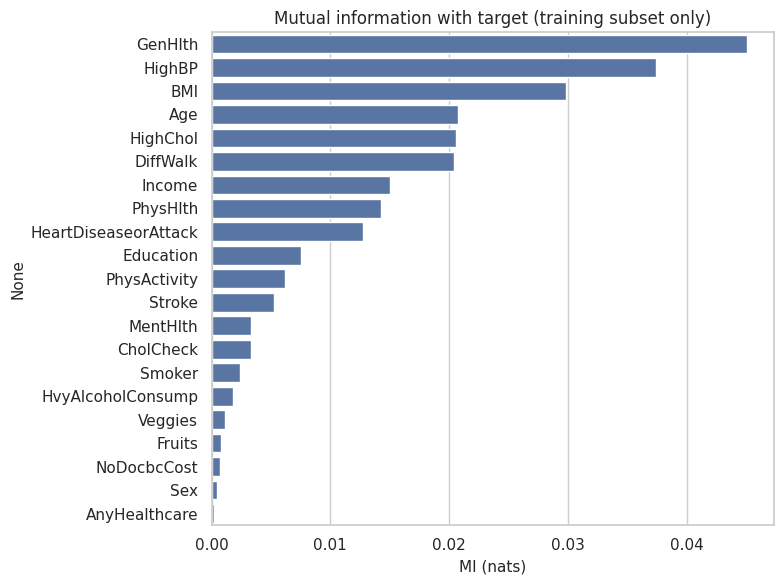

E9-MI-top8             PR-AUC 0.4149 | ROC-AUC 0.8217 | F1 0.229 | recall 0.145 | prec 0.544 | 4.3s
E9-MI-top12            PR-AUC 0.4176 | ROC-AUC 0.8233 | F1 0.241 | recall 0.154 | prec 0.555 | 6.1s
E9-MI-top16            PR-AUC 0.4222 | ROC-AUC 0.8265 | F1 0.249 | recall 0.161 | prec 0.548 | 5.9s


In [22]:
mi = pd.Series(mutual_info_classif(X_tune, y_tune, discrete_features=True, random_state=SEED), index=FEATURES).sort_values(ascending=False)
plt.figure(figsize=(8, 6)); sns.barplot(x=mi.values, y=mi.index, color="#4C72B0")
plt.title("Mutual information with target (training subset only)"); plt.xlabel("MI (nats)"); savefig("featsel_mutual_information")

e5_id = "E5-tuned-" + best_family; e5 = FITTED[e5_id]
for k in [8, 12, 16]:
    feats = mi.index[:k].tolist()
    run_trad(f"E9-MI-top{k}", best_family, f"{type(final_clf).__name__} on top-{k} MI features", clone(e5["pipe"].named_steps["clf"]), scale=e5["scale"],
             features=feats, notes=f"Features: {feats}", ref=e5_id, preproc_note=f"MI top-{k} (train-only) + impute{'+scale' if e5['scale'] else ''}")

## 10. Feature Selection (E9)

This experiment examines whether validation performance can be maintained with fewer than the original 21 features. A smaller feature set may simplify interpretation and reduce computational cost, but removing features can also discard useful information.

Features are ranked using mutual information calculated on a subset of the training data. Mutual information measures the dependence between a feature and the target and can identify relationships that are not strictly linear.

Using the selected Histogram Gradient Boosting configuration, models are trained with the top 8, 12 and 16 features. Their validation results are compared with the model using all 21 features. Feature ranking is based on training data only, so validation and test labels do not influence feature selection.

### Does Using Fewer Features Help?

Validation PR-AUC declined as the number of features decreased. The model using the top 8 features achieved 0.4149, the top 12 achieved 0.4176 and the top 16 achieved 0.4222. All three results were below the 0.4256 obtained by the tuned model using all 21 features.

The 16-feature model came closest to the full-feature result, with a difference of approximately 0.0034 PR-AUC. The 8-feature model had a larger difference of approximately 0.0107. Some features excluded from the smaller selections therefore appear to provide useful information, even when their individual mutual-information scores are relatively low.

Feature ranking evaluates each feature's information about the target but may not fully capture its contribution in combination with other features. The results do not support the assumption that the smallest feature set will perform as well as the full set.

The full 21-feature model is retained as the main traditional-model reference. The reduced-feature models provide useful comparisons, but their lower validation PR-AUC indicates a performance trade-off.

## 11. Deep Learning with TensorFlow/Keras

A feed-forward neural network is developed to compare its performance with the traditional machine learning models. It uses the same training, validation and test splits, and preprocessing transformations are fitted on the training data only.

Preprocessing includes imputation and standardisation. The transformed data are converted to `float32` arrays and passed to TensorFlow data pipelines. Training data are shuffled; validation and test data are not.

The network uses ReLU activation in its hidden layers and a sigmoid output layer for binary classification. Binary cross-entropy is the loss function, and Adam is the optimiser. ROC-AUC, PR-AUC and accuracy are tracked, with PR-AUC serving as the primary comparison metric because the target classes are imbalanced.

Early stopping monitors validation PR-AUC and restores the weights from the best epoch. When class weighting is used, weights are calculated from the training labels only. The output confirms the transformed dataset shapes and the class weights used in the experiments.

In [23]:
assert HAVE_TF, "TensorFlow is required for Sections 11-12 (it is preinstalled on Colab)."
prep_nn = make_prep(FEATURES, scale=True).fit(X_train)                  # fitted on TRAIN only
Xtr_nn, Xva_nn, Xte_nn = [prep_nn.transform(d).astype("float32") for d in (X_train, X_val, X_test)]
ytr_nn, yva_nn, yte_nn = [d.to_numpy().astype("float32") for d in (y_train, y_val, y_test)]
N_FEAT = Xtr_nn.shape[1]; print("Arrays:", Xtr_nn.shape, Xva_nn.shape, Xte_nn.shape)

def make_ds(X_, y_, batch, training=False):
    ds = tf.data.Dataset.from_tensor_slices((X_, y_)).cache()
    if training: ds = ds.shuffle(buffer_size=len(X_), seed=SEED, reshuffle_each_iteration=True)   # shuffle TRAIN only
    return ds.batch(batch).prefetch(tf.data.AUTOTUNE)

def class_weights_from(y_):
    n, n1 = len(y_), float(np.sum(y_)); return {0: n/(2*(n-n1)), 1: n/(2*n1)}      # computed from training labels only
CW = class_weights_from(ytr_nn); print("Class weights (from training labels):", {k: round(v, 3) for k, v in CW.items()})

def build_mlp(units=(64, 32), dropout=0.0, l2=0.0, lr=1e-3, optimizer="adam"):
    reg = keras.regularizers.l2(l2) if l2 > 0 else None
    layers = [keras.Input(shape=(N_FEAT,))]
    for u in units:
        layers.append(keras.layers.Dense(u, activation="relu", kernel_regularizer=reg))
        if dropout > 0: layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    model = keras.Sequential(layers)
    opt = {"adam": keras.optimizers.Adam, "rmsprop": keras.optimizers.RMSprop,
           "sgd": lambda learning_rate: keras.optimizers.SGD(learning_rate, momentum=0.9)}[optimizer](learning_rate=lr)
    model.compile(optimizer=opt, loss="binary_crossentropy",
                  metrics=[keras.metrics.AUC(name="roc_auc"), keras.metrics.AUC(curve="PR", name="pr_auc"), keras.metrics.BinaryAccuracy(name="accuracy")])
    return model

HISTORIES, NN_MODELS = {}, {}
def run_dl(exp_id, units=(64, 32), dropout=0.0, l2=0.0, lr=1e-3, batch=1024, optimizer="adam", class_weight=False, max_epochs=40, patience=5, notes="", ref=None):
    keras.utils.set_random_seed(SEED); keras.backend.clear_session()
    train_ds, val_ds = make_ds(Xtr_nn, ytr_nn, batch, True), make_ds(Xva_nn, yva_nn, 4096)
    model = build_mlp(units, dropout, l2, lr, optimizer)
    es = keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=patience, restore_best_weights=True)
    t0 = time.perf_counter()
    hist = model.fit(train_ds, validation_data=val_ds, epochs=max_epochs, callbacks=[es], class_weight=CW if class_weight else None, verbose=0)
    rt = time.perf_counter() - t0
    proba = model.predict(val_ds, verbose=0).ravel(); m = compute_metrics(yva_nn, proba)
    best_ep = int(np.argmax(hist.history["val_pr_auc"])) + 1; n_ep = len(hist.history["loss"])
    params = dict(units=list(units), dropout=dropout, l2=l2, learning_rate=lr, batch_size=batch, optimizer=optimizer, class_weight=class_weight,
                  max_epochs=max_epochs, early_stopping=f"val_pr_auc, patience={patience}, restore_best_weights", loss="binary_crossentropy", n_parameters=int(model.count_params()))
    tracker.log(exp_id, "Deep learning", "MLP", f"Keras Sequential MLP {list(units)}", params, "impute+standardise numeric (train-fit); tf.data pipeline",
                SPLIT_DESC + "; early stopping on validation", m, rt, notes, ref, history=hist.history,
                extra={"n_features": N_FEAT, "epochs_run": n_ep, "best_epoch": best_ep})
    HISTORIES[exp_id] = hist.history; NN_MODELS[exp_id] = model; VAL_PROBA[exp_id] = proba
    print(f"{exp_id:<22} PR-AUC {m['pr_auc']:.4f} | ROC-AUC {m['roc_auc']:.4f} | F1 {m['f1']:.3f} | recall {m['recall']:.3f} | epochs {n_ep} (best {best_ep}) | {rt:.0f}s")
    return m

Arrays: (177576, 21) (38052, 21) (38052, 21)
Class weights (from training labels): {0: 0.581, 1: 3.589}


## 12. Deep-Learning Experiments

Eight neural-network experiments examine how architecture, regularisation, learning rate, class weights and batch size affect validation performance.

The baseline network uses two hidden layers with 64 and 32 units, a learning rate of 0.001 and a batch size of 1,024. The remaining experiments change selected settings relative to this baseline.

All experiments use the same data splits and preprocessing. Each model trains for up to 40 epochs, with early stopping based on validation PR-AUC and a patience of five epochs. The weights from the best epoch are restored.

The experiments provide a controlled comparison of selected settings; a deeper network or a different hyperparameter value is not assumed to perform better without supporting results.

In [24]:
run_dl("DL-E1-base",          units=(64, 32),      notes="Baseline MLP")
run_dl("DL-E2a-small",        units=(16, 8),       notes="Capacity: smaller network", ref="DL-E1-base")
run_dl("DL-E2b-deep",         units=(128, 64, 32), notes="Capacity: larger/deeper network", ref="DL-E1-base")
run_dl("DL-E3-reg",           units=(128, 64),     dropout=0.3, l2=1e-4, notes="Regularisation: dropout 0.3 + L2 1e-4", ref="DL-E1-base")
run_dl("DL-E4a-lr3e-4",       units=(64, 32),      lr=3e-4, notes="Learning rate lower", ref="DL-E1-base")
run_dl("DL-E4b-lr3e-3",       units=(64, 32),      lr=3e-3, notes="Learning rate higher", ref="DL-E1-base")
run_dl("DL-E5a-classweight",  units=(64, 32),      class_weight=True, notes="Class-weighted BCE (weights from training labels)", ref="DL-E1-base")
run_dl("DL-E5b-batch256",     units=(64, 32),      batch=256, notes="Batch size 256", ref="DL-E1-base")

DL-E1-base             PR-AUC 0.4294 | ROC-AUC 0.8284 | F1 0.257 | recall 0.167 | epochs 24 (best 19) | 35s
DL-E2a-small           PR-AUC 0.4247 | ROC-AUC 0.8270 | F1 0.247 | recall 0.160 | epochs 26 (best 21) | 34s
DL-E2b-deep            PR-AUC 0.4287 | ROC-AUC 0.8290 | F1 0.316 | recall 0.226 | epochs 12 (best 7) | 18s
DL-E3-reg              PR-AUC 0.4297 | ROC-AUC 0.8290 | F1 0.216 | recall 0.133 | epochs 22 (best 17) | 32s
DL-E4a-lr3e-4          PR-AUC 0.4256 | ROC-AUC 0.8279 | F1 0.231 | recall 0.146 | epochs 40 (best 39) | 51s
DL-E4b-lr3e-3          PR-AUC 0.4267 | ROC-AUC 0.8280 | F1 0.318 | recall 0.229 | epochs 12 (best 7) | 16s
DL-E5a-classweight     PR-AUC 0.4271 | ROC-AUC 0.8281 | F1 0.435 | recall 0.809 | epochs 15 (best 10) | 22s
DL-E5b-batch256        PR-AUC 0.4283 | ROC-AUC 0.8280 | F1 0.267 | recall 0.176 | epochs 12 (best 7) | 46s


{'accuracy': 0.8649742457689478,
 'precision': 0.5480656506447831,
 'recall': 0.17634854771784234,
 'f1': 0.266837899543379,
 'roc_auc': np.float64(0.8279514370207411),
 'pr_auc': np.float64(0.4282976961109637),
 'threshold': 0.5}

,exp_id,accuracy,precision,recall,f1,roc_auc,pr_auc,epochs_run,best_epoch,runtime_s
17,DL-E1-base,0.8652,0.5538,0.1669,0.2565,0.8284,0.4294,24.000000,19.000000,35
18,DL-E2a-small,0.8639,0.5397,0.1603,0.2472,0.8270,0.4247,26.000000,21.000000,34
19,DL-E2b-deep,0.8639,0.5271,0.2260,0.3163,0.8290,0.4287,12.000000,7.000000,18
20,DL-E3-reg,0.8655,0.5746,0.1330,0.2160,0.8290,0.4297,22.000000,17.000000,32
21,DL-E4a-lr3e-4,0.8651,0.5619,0.1456,0.2313,0.8279,0.4256,40.000000,39.000000,51
22,DL-E4b-lr3e-3,0.8632,0.5206,0.2288,0.3179,0.8280,0.4267,12.000000,7.000000,16
23,DL-E5a-classweight,0.7073,0.2976,0.8089,0.4351,0.8281,0.4271,15.000000,10.000000,22
24,DL-E5b-batch256,0.8650,0.5481,0.1763,0.2668,0.8280,0.4283,12.000000,7.000000,46


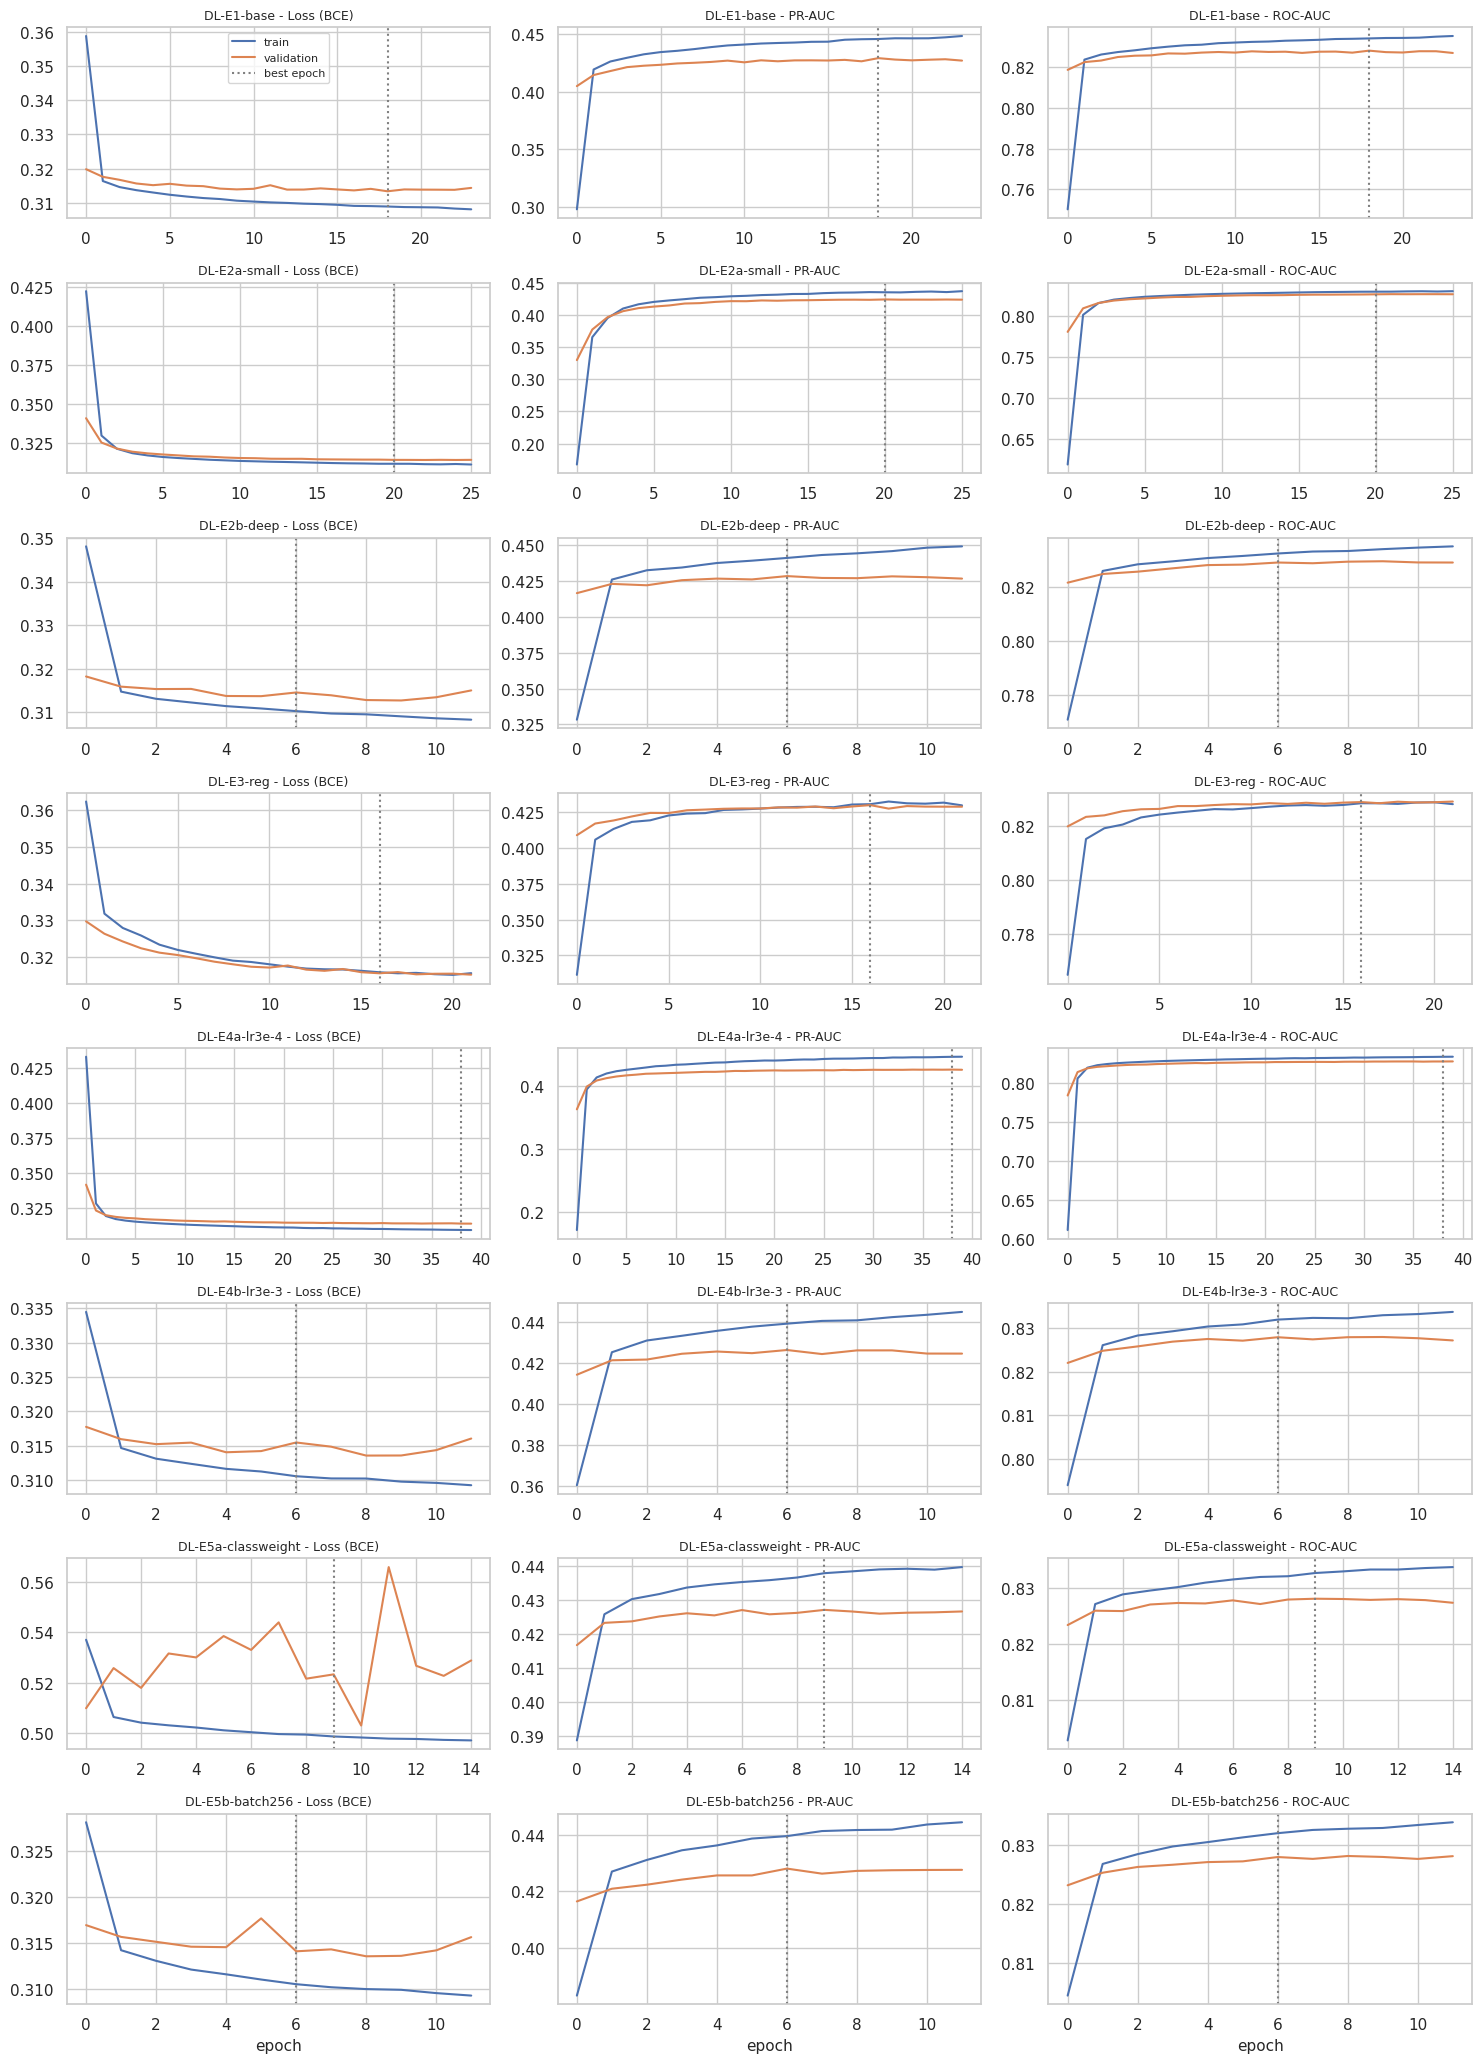

In [25]:
dl = tracker.table(); dl = dl[dl.paradigm == "Deep learning"]
cols = ["exp_id", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "epochs_run", "best_epoch", "runtime_s"]
display(dl[cols].style.format({c: "{:.4f}" for c in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]} | {"runtime_s": "{:.0f}"}))

fig, axes = plt.subplots(len(HISTORIES), 3, figsize=(15, 2.6*len(HISTORIES)), sharex=False)
for r, (eid, h) in enumerate(HISTORIES.items()):
    for c, (k, lab) in enumerate([("loss", "Loss (BCE)"), ("pr_auc", "PR-AUC"), ("roc_auc", "ROC-AUC")]):
        a = axes[r, c]; a.plot(h[k], label="train"); a.plot(h["val_"+k], label="validation")
        a.axvline(int(np.argmax(h["val_pr_auc"])), color="grey", ls=":", label="best epoch"); a.set_title(f"{eid} - {lab}", fontsize=9)
        if r == 0 and c == 0: a.legend(fontsize=8)
        if r == len(HISTORIES)-1: a.set_xlabel("epoch")
savefig("dl_learning_curves_all_runs")
json.dump({k: {m: [float(x) for x in v] for m, v in h.items()} for k, h in HISTORIES.items()}, open(RES/"nn_training_histories.json", "w"))

### Interpretation: Neural-Network Experiments

The results show that changes to the network settings affected performance, but deeper or more regularised models did not improve every metric.

The baseline model achieved a validation PR-AUC of 0.4294. The smaller network achieved 0.4247, the deeper network achieved 0.4287, and the regularised model DL-E3-reg achieved the highest validation PR-AUC among the eight experiments at 0.4297.

The learning-rate experiments also differed in training behaviour. The lower learning rate of 0.0003 reached its best epoch at epoch 39 and ran for all 40 epochs. The higher learning rate of 0.003 reached its best epoch at epoch 7 and stopped after 12 epochs. The learning curves should be examined alongside these summary values before drawing conclusions about convergence or overfitting.

Class weighting affected the default-threshold results. DL-E5a-classweight achieved recall of 0.809 and an F1-score of 0.435 at the 0.5 threshold. Its PR-AUC was 0.4271, below the regularised model's 0.4297. In this experiment, class weighting changed the precision-recall balance more noticeably than it improved ranking performance.

The leading PR-AUC values are close, so the small differences do not establish that one configuration is consistently superior. Repeated runs with different random seeds would help assess the stability of the ranking. The next section brings the experiment configurations and results together.

## 13. Experiment Tracking

Experiment tracking keeps model configurations, evaluation metrics and training information together. Each traditional machine learning and neural-network experiment is recorded in a JSONL log and a Weights & Biases offline run.

The neural-network logs also include training histories, allowing the metrics to be reviewed across epochs. The records can be inspected locally without uploading them to an online service.

The output reports 25 records in memory, 25 lines in the JSONL file and 25 offline Weights & Biases run folders. Uploading the offline runs to the Weights & Biases website is optional; the JSONL log and exported result tables are sufficient for local review.

In [26]:
jl = LOGS/"experiment_log.jsonl"
n_jsonl = sum(1 for _ in open(jl))
wb_runs = sorted((LOGS/"wandb").glob("offline-run-*")) if (LOGS/"wandb").exists() else []
print(f"Records in memory: {len(tracker.records)} | JSONL lines: {n_jsonl} | W&B offline run folders: {len(wb_runs)}")
for p in wb_runs[:5]: print(" ", p)
print("..." if len(wb_runs) > 5 else "")
print("W&B mode was:", os.environ.get("WANDB_MODE"))

Records in memory: 25 | JSONL lines: 25 | W&B offline run folders: 25
  outputs/logs/wandb/offline-run-20261014_185944-wy8lcey3
  outputs/logs/wandb/offline-run-20261014_185958-rvmoh3gx
  outputs/logs/wandb/offline-run-20261014_190002-s8k366n2
  outputs/logs/wandb/offline-run-20261014_190007-b00399b8
  outputs/logs/wandb/offline-run-20261014_190011-jezzc9wd
...
W&B mode was: offline


## 14. Consolidated Experiment Results

This section combines the results from all experiments in one table. It includes the experiment ID, model, configuration, preprocessing, evaluation split, performance metrics, runtime and notes describing the change from the reference experiment.

The table contains 25 validation experiments: 17 traditional machine learning runs and eight neural-network runs. The results are generated from the experiment tracker, reducing the risk of errors from manually copying metrics between sections.

PR-AUC is the primary comparison metric because class 1 is the minority class. Accuracy, precision, recall, F1-score and ROC-AUC provide complementary information about model performance.

The validation results are exported to CSV, and the accompanying chart compares PR-AUC across the recorded experiments. The held-out test evaluation is reported separately in the next section.

25 validation experiments recorded (17 traditional, 8 deep learning).


,exp_id,paradigm,model,hyperparameters,preprocessing,eval_split,accuracy,precision,recall,f1,roc_auc,pr_auc,runtime_s,observation
0,E1-dummy,Traditional ML,DummyClassifier(most_frequent),"{""strategy"": ""most_frequent""}",impute(median/mode)+no scaling; 21 features,validation,0.8607,0.0000,0.0000,0.0000,0.5000,0.1393,0.2,"validation PR-AUC 0.1393; recall 0.000, precision 0.000"
1,E2-LR-C0.01-nocw,Traditional ML,LogisticRegression(L2),"{""C"": 0.01, ""max_iter"": 1000, ""random_state"": 42}",impute(median/mode)+standardise numeric; 21 features,validation,0.8638,0.5382,0.1569,0.2430,0.8207,0.4034,1.2,"validation PR-AUC 0.4034 (+0.2641 vs E1-dummy); recall 0.157, precision 0.538"
2,E2-LR-C0.1-nocw,Traditional ML,LogisticRegression(L2),"{""C"": 0.1, ""max_iter"": 1000, ""random_state"": 42}",impute(median/mode)+standardise numeric; 21 features,validation,0.8639,0.5384,0.1614,0.2484,0.8209,0.4038,1.3,"validation PR-AUC 0.4038 (+0.2645 vs E1-dummy); recall 0.161, precision 0.538"
3,E2-LR-C1.0-nocw,Traditional ML,LogisticRegression(L2),"{""max_iter"": 1000, ""random_state"": 42}",impute(median/mode)+standardise numeric; 21 features,validation,0.8639,0.5383,0.1618,0.2488,0.8209,0.4039,1.4,"validation PR-AUC 0.4039 (+0.2645 vs E1-dummy); recall 0.162, precision 0.538"
4,E2-LR-C0.01-bal,Traditional ML,LogisticRegression(L2),"{""C"": 0.01, ""class_weight"": ""balanced"", ""max_iter"": 1000, ""random_state"": 42}",impute(median/mode)+standardise numeric; 21 features,validation,0.7301,0.3094,0.7610,0.4400,0.8214,0.4018,1.2,"validation PR-AUC 0.4018 (+0.2625 vs E1-dummy); recall 0.761, precision 0.309"
5,E2-LR-C0.1-bal,Traditional ML,LogisticRegression(L2),"{""C"": 0.1, ""class_weight"": ""balanced"", ""max_iter"": 1000, ""random_state"": 42}",impute(median/mode)+standardise numeric; 21 features,validation,0.7302,0.3096,0.7610,0.4401,0.8215,0.4020,1.2,"validation PR-AUC 0.4020 (+0.2626 vs E1-dummy); recall 0.761, precision 0.310"
6,E2-LR-C1.0-bal,Traditional ML,LogisticRegression(L2),"{""class_weight"": ""balanced"", ""max_iter"": 1000, ""random_state"": 42}",impute(median/mode)+standardise numeric; 21 features,validation,0.7302,0.3095,0.7608,0.4400,0.8215,0.4020,1.4,"validation PR-AUC 0.4020 (+0.2627 vs E1-dummy); recall 0.761, precision 0.310"
7,E3-RF-100t-d10,Traditional ML,RandomForestClassifier,"{""max_depth"": 10, ""min_samples_leaf"": 5, ""n_jobs"": -1, ""random_state"": 42}",impute(median/mode)+no scaling; 21 features,validation,0.8644,0.5877,0.0903,0.1566,0.8228,0.4200,7.6,"validation PR-AUC 0.4200 (+0.0161 vs E2-LR-C1.0-nocw); recall 0.090, precision 0.588"
8,E3-RF-200t-d16,Traditional ML,RandomForestClassifier,"{""max_depth"": 16, ""min_samples_leaf"": 20, ""n_estimators"": 200, ""n_jobs"": -1, ""random_state"": 42}",impute(median/mode)+no scaling; 21 features,validation,0.8646,0.5744,0.1084,0.1825,0.8245,0.4248,18.3,"validation PR-AUC 0.4248 (+0.0209 vs E2-LR-C1.0-nocw); recall 0.108, precision 0.574"
9,E3-RF-200t-d16-bal,Traditional ML,RandomForestClassifier,"{""class_weight"": ""balanced_subsample"", ""max_depth"": 16, ""min_samples_leaf"": 20, ""n_estimators"": 200, ""n_jobs"": -1, ""random_state"": 42}",impute(median/mode)+no scaling; 21 features,validation,0.7420,0.3196,0.7544,0.4490,0.8252,0.4236,23.6,"validation PR-AUC 0.4236 (+0.0197 vs E2-LR-C1.0-nocw); recall 0.754, precision 0.320"


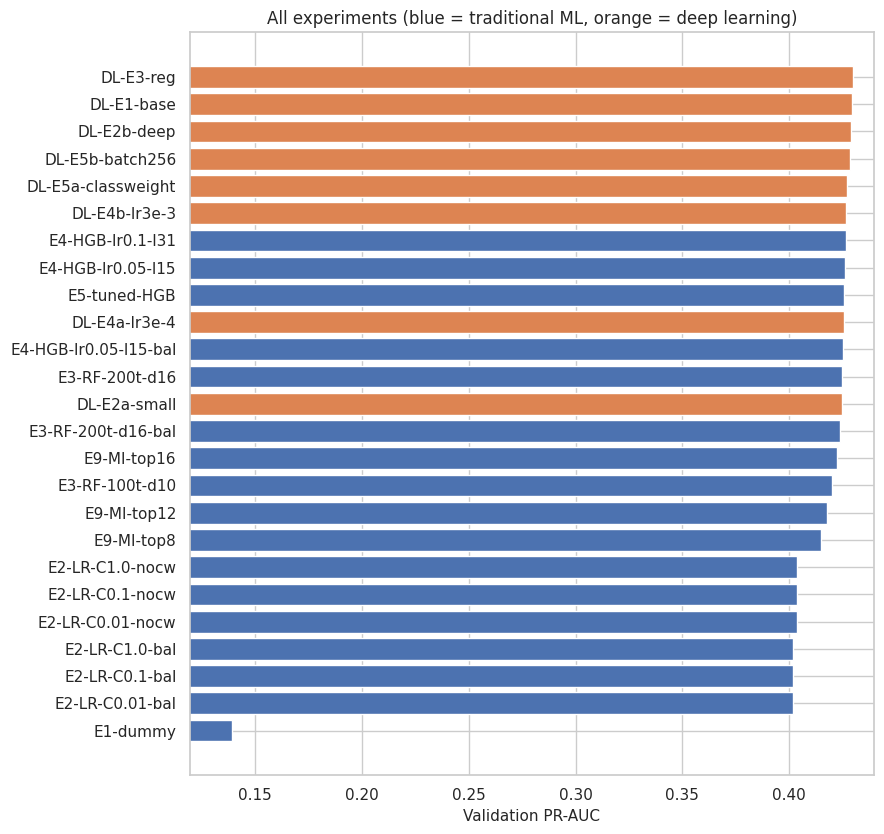

In [27]:
pd.set_option("display.max_colwidth", 140, "display.width", 250)
def results_table():
    t = tracker.table()
    keep = ["exp_id", "paradigm", "model", "hyperparameters", "preprocessing", "protocol", "eval_split", "accuracy", "precision", "recall", "f1",
            "roc_auc", "pr_auc", "runtime_s", "observation", "notes"]
    return t[[c for c in keep if c in t.columns]]
RT = results_table(); val_rt = RT[RT.eval_split == "validation"]
print(f"{len(val_rt)} validation experiments recorded ({(val_rt.paradigm == 'Traditional ML').sum()} traditional, {(val_rt.paradigm == 'Deep learning').sum()} deep learning).")
assert len(val_rt) >= 7, "Fewer than 7 experiments recorded."
display(val_rt.drop(columns=["protocol", "notes"]).style.format({c: "{:.4f}" for c in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc"]} | {"runtime_s": "{:.1f}"}, na_rep="n/a"))
val_rt.to_csv(RES/"experiment_results_validation.csv", index=False)

order = val_rt.sort_values("pr_auc"); colors = order.paradigm.map({"Traditional ML": "#4C72B0", "Deep learning": "#DD8452"})
plt.figure(figsize=(9, 0.28*len(order)+1.5)); plt.barh(order.exp_id, order.pr_auc, color=colors)
plt.xlim(max(0, order.pr_auc.min()-0.02), order.pr_auc.max()+0.01); plt.xlabel("Validation PR-AUC"); plt.title("All experiments (blue = traditional ML, orange = deep learning)")
savefig("results_validation_pr_auc_all_experiments")

In [28]:
t_all = tracker.table(); t_all = t_all[t_all.eval_split == "validation"]
bt = t_all[(t_all.paradigm == "Traditional ML") & (t_all.family != "Dummy")].sort_values("pr_auc", ascending=False)
bd = t_all[t_all.paradigm == "Deep learning"].sort_values("pr_auc", ascending=False)
dummy = t_all[t_all.family == "Dummy"].iloc[0]
fam_best = bt.groupby("family").pr_auc.max().sort_values(ascending=False)
txt = [f"**Automatic summary of recorded validation results (computed, not typed).**",
       f"- Majority baseline: accuracy {dummy.accuracy:.3f}, recall {dummy.recall:.3f}, PR-AUC {dummy.pr_auc:.3f} (= positive prevalence).",
       "- Best validation PR-AUC by traditional family: " + ", ".join(f"{k} {x:.4f}" for k, x in fam_best.items()) + ".",
       f"- Best traditional run: **{bt.iloc[0].exp_id}** (PR-AUC {bt.iloc[0].pr_auc:.4f}, ROC-AUC {bt.iloc[0].roc_auc:.4f}, {bt.iloc[0].runtime_s:.1f}s).",
       f"- Best neural-network run: **{bd.iloc[0].exp_id}** (PR-AUC {bd.iloc[0].pr_auc:.4f}, ROC-AUC {bd.iloc[0].roc_auc:.4f}, {bd.iloc[0].runtime_s:.0f}s).",
       f"- Gap (NN - best traditional) in validation PR-AUC: {bd.iloc[0].pr_auc-bt.iloc[0].pr_auc:+.4f}; spread among all non-dummy runs: {t_all[t_all.family!='Dummy'].pr_auc.max()-t_all[t_all.family!='Dummy'].pr_auc.min():.4f}."]
display(Markdown("\n".join(txt)))

**Automatic summary of recorded validation results (computed, not typed).**
- Majority baseline: accuracy 0.861, recall 0.000, PR-AUC 0.139 (= positive prevalence).
- Best validation PR-AUC by traditional family: HGB 0.4266, RF 0.4248, LR 0.4039.
- Best traditional run: **E4-HGB-lr0.1-l31** (PR-AUC 0.4266, ROC-AUC 0.8283, 3.9s).
- Best neural-network run: **DL-E3-reg** (PR-AUC 0.4297, ROC-AUC 0.8290, 32s).
- Gap (NN - best traditional) in validation PR-AUC: +0.0031; spread among all non-dummy runs: 0.0279.

### Interpretation: Consolidated Experiment Results

The results show that the model with the highest validation PR-AUC is not necessarily the model with the highest recall or F1-score at the default threshold.

Among the traditional models, the original Histogram Gradient Boosting experiment achieved a validation PR-AUC of 0.4266. The tuned model achieved 0.4256, so tuning did not improve this validation metric. Feature selection also reduced PR-AUC: the top-16-feature model achieved 0.4222, compared with 0.4256 for the tuned model using all features.

Among the neural networks, DL-E3-reg achieved the highest validation PR-AUC at 0.4297. This is 0.0031 higher than the best initial traditional run at 0.4266. The difference is small; the results suggest that the neural network was competitive on validation PR-AUC rather than clearly superior.

Class weighting changed the precision-recall balance more noticeably than it changed PR-AUC. For example, the class-weighted neural network achieved recall of 0.809 at the default threshold, with a PR-AUC of 0.4271. This supports comparing multiple metrics rather than relying on accuracy alone.

The strongest result did not necessarily come from the most complex configuration. Small differences between leading models should be interpreted cautiously, and repeated runs or cross-validation would help assess the stability of their ranking. Runtime is also relevant: the neural-network experiments generally took longer than the initial Histogram Gradient Boosting run, although timings vary by environment. Model selection should consider predictive performance and computational cost together.

## 15. Final Model Selection and One-Time Test Evaluation

The best non-baseline traditional model and the neural network were selected using validation PR-AUC. The test set remained separate during model selection so that it could provide a final evaluation on data not used to choose the models.

For each selected model, the classification threshold was chosen using validation data by selecting the value that maximised F1-score over the specified threshold grid. The selected threshold was then fixed for the test evaluation. Results at the default threshold of 0.5 are also reported for comparison.

The selected traditional model is `E4-HGB-lr0.1-l31`, and the selected neural network is `DL-E3-reg`. Their validation-selected thresholds are 0.27 and 0.23, respectively.

The test results compare precision, recall, F1-score, ROC-AUC, PR-AUC and accuracy. Because this is the final held-out evaluation, test results should not be used to revise model configurations or thresholds.

In [29]:
t_all = tracker.table(); t_val = t_all[t_all.eval_split == "validation"]
BEST_TRAD = t_val[(t_val.paradigm == "Traditional ML") & (t_val.family != "Dummy")].sort_values("pr_auc", ascending=False).iloc[0].exp_id
BEST_DL   = t_val[t_val.paradigm == "Deep learning"].sort_values("pr_auc", ascending=False).iloc[0].exp_id
print("Selected (by validation PR-AUC):  traditional =", BEST_TRAD, "| neural network =", BEST_DL)

def pick_threshold(y_true, proba):
    grid = np.round(np.arange(0.02, 0.981, 0.01), 2); f1s = [f1_score(y_true, (proba >= t).astype(int), zero_division=0) for t in grid]
    return float(grid[int(np.argmax(f1s))])
THR = {"Dummy": 0.5, BEST_TRAD: pick_threshold(y_val, VAL_PROBA[BEST_TRAD]), BEST_DL: pick_threshold(y_val, VAL_PROBA[BEST_DL])}
print("Validation-selected thresholds:", THR)
FINAL_CONFIG = {"best_traditional": BEST_TRAD, "best_neural_network": BEST_DL, "thresholds": THR, "selection_criterion": "max validation PR-AUC; threshold = argmax validation F1"}

# ---- the single test-set evaluation ----
bt_info = FITTED[BEST_TRAD]
TEST_PROBA = {"Dummy": FITTED["E1-dummy"]["pipe"].predict_proba(X_test)[:, 1],
              BEST_TRAD: bt_info["pipe"].predict_proba(X_test[bt_info["features"]])[:, 1],
              BEST_DL: NN_MODELS[BEST_DL].predict(make_ds(Xte_nn, yte_nn, 4096), verbose=0).ravel()}
LABELS = {"Dummy": "Majority baseline", BEST_TRAD: f"Best traditional ({BEST_TRAD})", BEST_DL: f"Best neural net ({BEST_DL})"}
rows = []
for key, pr in TEST_PROBA.items():
    for tag, thr in [("thr=0.50", 0.5), ("thr=val-tuned", THR[key])]:
        if key == "Dummy" and tag != "thr=0.50": continue
        m = compute_metrics(y_test, pr, thr); rows.append({"model": LABELS[key], "threshold_rule": tag, **m})
        tracker.log(f"E10-{key}-{tag}", "Final comparison", "final", LABELS[key], {"threshold": thr, "source_experiment": key}, "as source experiment",
                    "held-out test set (15%), evaluated once", m, 0.0, "Final comparison on untouched test set", eval_split="test")
TEST_TBL = pd.DataFrame(rows); display(TEST_TBL.style.format({c: "{:.4f}" for c in ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "threshold"]}))
TEST_TBL.to_csv(RES/"final_test_metrics.csv", index=False)
for key in [BEST_TRAD, BEST_DL]:
    print("\n" + LABELS[key], f"(threshold {THR[key]})"); print(classification_report(y_test, (TEST_PROBA[key] >= THR[key]).astype(int), target_names=["class 0 (no reported diabetes)", "class 1 (reported diabetes)"], digits=3))

Selected (by validation PR-AUC):  traditional = E4-HGB-lr0.1-l31 | neural network = DL-E3-reg
Validation-selected thresholds: {'Dummy': 0.5, 'E4-HGB-lr0.1-l31': 0.27, 'DL-E3-reg': 0.23}


,model,threshold_rule,accuracy,precision,recall,f1,roc_auc,pr_auc,threshold
0,Majority baseline,thr=0.50,0.8607,0.0000,0.0000,0.0000,0.5000,0.1393,0.5000
1,Best traditional (E4-HGB-lr0.1-l31),thr=0.50,0.8668,0.5800,0.1607,0.2517,0.8293,0.4270,0.5000
2,Best traditional (E4-HGB-lr0.1-l31),thr=val-tuned,0.8264,0.4063,0.5328,0.4610,0.8293,0.4270,0.2700
3,Best neural net (DL-E3-reg),thr=0.50,0.8671,0.6012,0.1379,0.2243,0.8299,0.4275,0.5000
4,Best neural net (DL-E3-reg),thr=val-tuned,0.8070,0.3811,0.6169,0.4712,0.8299,0.4275,0.2300



Best traditional (E4-HGB-lr0.1-l31) (threshold 0.27)
                                precision    recall  f1-score   support

class 0 (no reported diabetes)      0.920     0.874     0.897     32750
   class 1 (reported diabetes)      0.406     0.533     0.461      5302

                      accuracy                          0.826     38052
                     macro avg      0.663     0.703     0.679     38052
                  weighted avg      0.849     0.826     0.836     38052


Best neural net (DL-E3-reg) (threshold 0.23)
                                precision    recall  f1-score   support

class 0 (no reported diabetes)      0.931     0.838     0.882     32750
   class 1 (reported diabetes)      0.381     0.617     0.471      5302

                      accuracy                          0.807     38052
                     macro avg      0.656     0.727     0.677     38052
                  weighted avg      0.854     0.807     0.825     38052



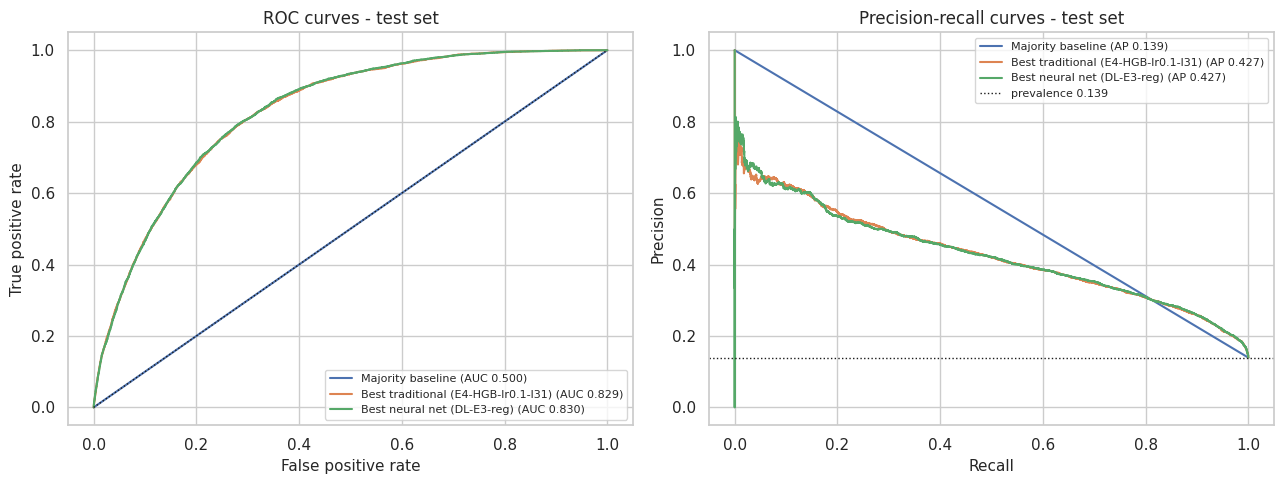

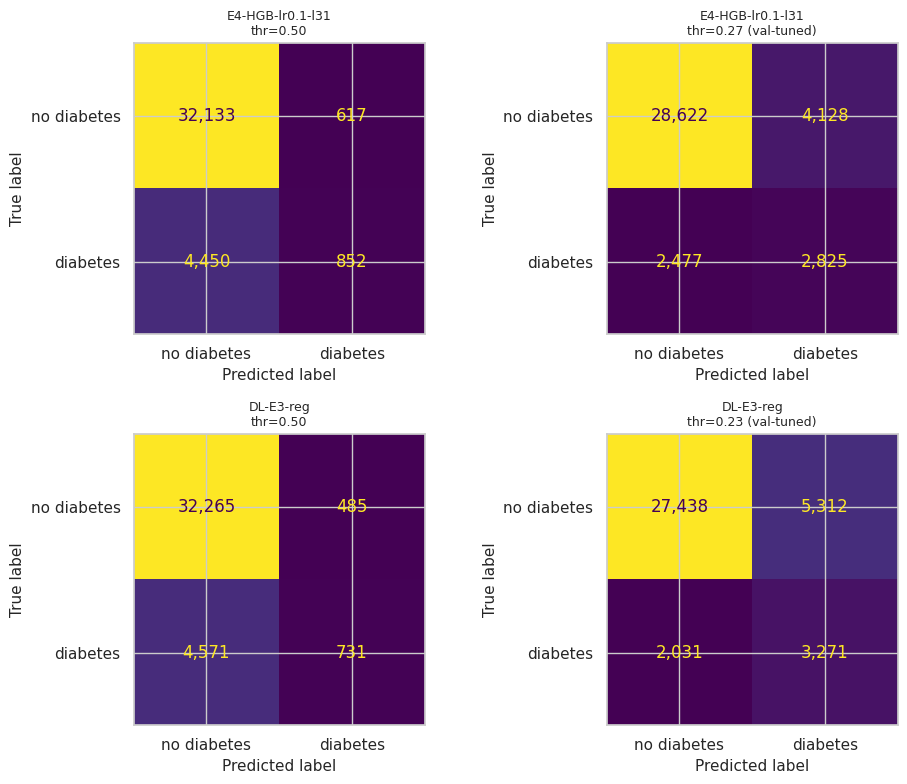

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for key, pr in TEST_PROBA.items():
    fpr, tpr, _ = roc_curve(y_test, pr); ax[0].plot(fpr, tpr, label=f"{LABELS[key]} (AUC {roc_auc_score(y_test, pr):.3f})")
    p, r, _ = precision_recall_curve(y_test, pr); ax[1].plot(r, p, label=f"{LABELS[key]} (AP {average_precision_score(y_test, pr):.3f})")
ax[0].plot([0, 1], [0, 1], "k:", lw=1); ax[0].set(title="ROC curves - test set", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend(fontsize=8)
ax[1].axhline(y_test.mean(), color="k", ls=":", lw=1, label=f"prevalence {y_test.mean():.3f}"); ax[1].set(title="Precision-recall curves - test set", xlabel="Recall", ylabel="Precision"); ax[1].legend(fontsize=8)
savefig("final_roc_pr_curves")

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for r_, key in enumerate([BEST_TRAD, BEST_DL]):
    for c_, (tag, thr) in enumerate([("thr=0.50", 0.5), (f"thr={THR[key]:.2f} (val-tuned)", THR[key])]):
        cm = confusion_matrix(y_test, (TEST_PROBA[key] >= thr).astype(int))
        ConfusionMatrixDisplay(cm, display_labels=["no diabetes", "diabetes"]).plot(ax=axes[r_, c_], colorbar=False, values_format=",d")
        axes[r_, c_].set_title(f"{key}\n{tag}", fontsize=9)
savefig("final_confusion_matrices")

### Interpretation: Test Results

Both selected models performed better than the majority-class baseline on metrics relevant to identifying respondents who reported diabetes.

The traditional Histogram Gradient Boosting model achieved a test PR-AUC of 0.4270, while the neural network achieved 0.4275. The difference of 0.0005 is very small, indicating similar PR-AUC performance on the test set.

At the thresholds selected using validation data, the traditional model achieved precision of 0.406, recall of 0.533 and an F1-score of 0.461. The neural network achieved precision of 0.381, recall of 0.617 and an F1-score of 0.471. The neural network identified a larger proportion of positive cases but also produced more false positives.

At the default threshold of 0.5, both models had higher accuracy but much lower recall: 0.161 for the traditional model and 0.138 for the neural network. Lowering the thresholds increased recall and F1-score while reducing accuracy and precision. Threshold choice therefore affects the balance between missed positive cases and false alarms.

The majority-class baseline achieved 86.07% accuracy but had zero recall and F1-score for class 1 because it predicts class 0 for every respondent. Its accuracy does not indicate that it can identify respondents who report diabetes.

The ROC-AUC scores were 0.8293 for the traditional model and 0.8299 for the neural network. These results, together with the similar test PR-AUC values, indicate broadly comparable ranking performance. However, they do not remove limitations associated with duplicate feature patterns or the self-reported target.

Overall, the neural network achieved slightly higher recall and F1-score at its selected threshold, while the traditional model achieved higher precision and accuracy. Neither model outperformed the other across every metric. These results compare models on this dataset and do not establish readiness for clinical use.

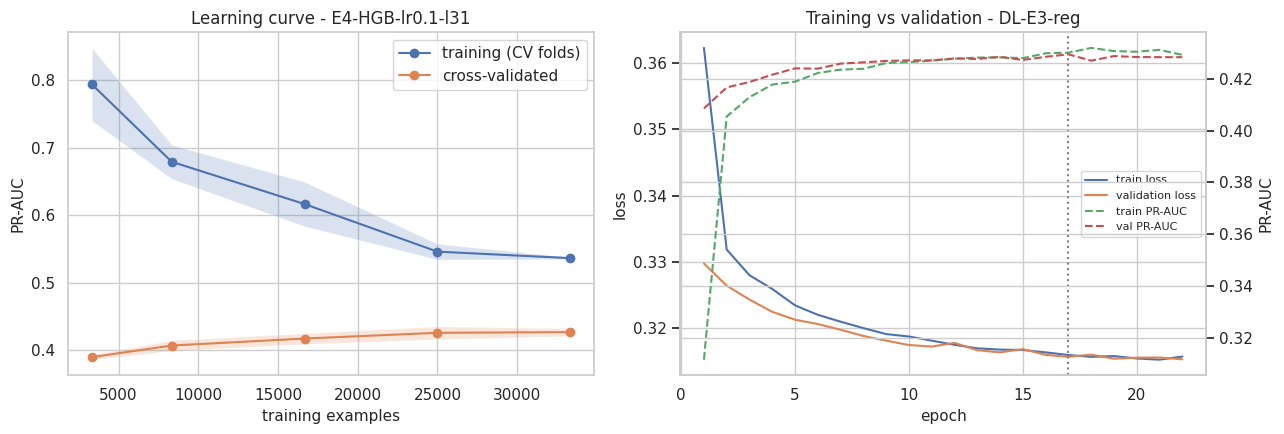

Traditional learning curve at full subset: train PR-AUC 0.5363, CV PR-AUC 0.4268, gap 0.1096; CV PR-AUC change over last two sizes: +0.0010
NN: final train PR-AUC 0.4293 vs validation 0.4284; epochs run 22, best epoch 17


In [31]:
feats = bt_info["features"]; sizes = [0.1, 0.25, 0.5, 0.75, 1.0]
lc_pipe = clone(Pipeline([("prep", make_prep(feats, bt_info["scale"])), ("clf", clone(bt_info["pipe"].named_steps["clf"]))]))
ts, trs, vas = learning_curve(lc_pipe, X_tune[feats], y_tune, train_sizes=sizes, cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                              scoring="average_precision", n_jobs=1, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a_, (arr, lab) in zip([ax[0]]*2, [(trs, "training (CV folds)"), (vas, "cross-validated")]):
    a_.plot(ts, arr.mean(1), marker="o", label=lab); a_.fill_between(ts, arr.mean(1)-arr.std(1), arr.mean(1)+arr.std(1), alpha=.2)
ax[0].set(title=f"Learning curve - {BEST_TRAD}", xlabel="training examples", ylabel="PR-AUC"); ax[0].legend()
h = HISTORIES[BEST_DL]; ep = np.arange(1, len(h["loss"])+1)
ax[1].plot(ep, h["loss"], label="train loss"); ax[1].plot(ep, h["val_loss"], label="validation loss"); ax2 = ax[1].twinx()
ax2.plot(ep, h["pr_auc"], "--", color="C2", label="train PR-AUC"); ax2.plot(ep, h["val_pr_auc"], "--", color="C3", label="val PR-AUC")
ax[1].axvline(int(np.argmax(h["val_pr_auc"]))+1, color="grey", ls=":"); ax[1].set(title=f"Training vs validation - {BEST_DL}", xlabel="epoch", ylabel="loss"); ax2.set_ylabel("PR-AUC")
l1, n1 = ax[1].get_legend_handles_labels(); l2, n2 = ax2.get_legend_handles_labels(); ax[1].legend(l1+l2, n1+n2, fontsize=8, loc="center right")
savefig("learning_curves_best_models")
gap = trs.mean(1)[-1]-vas.mean(1)[-1]
print(f"Traditional learning curve at full subset: train PR-AUC {trs.mean(1)[-1]:.4f}, CV PR-AUC {vas.mean(1)[-1]:.4f}, gap {gap:.4f}; "
      f"CV PR-AUC change over last two sizes: {vas.mean(1)[-1]-vas.mean(1)[-2]:+.4f}")
print(f"NN: final train PR-AUC {h['pr_auc'][-1]:.4f} vs validation {h['val_pr_auc'][-1]:.4f}; epochs run {len(ep)}, best epoch {int(np.argmax(h['val_pr_auc']))+1}")

In [32]:
key = BEST_TRAD; pred = (TEST_PROBA[key] >= THR[key]).astype(int)
E = X_test.copy(); E["y"] = y_test.values; E["pred"] = pred
E["outcome"] = np.select([(E.y == 1) & (E.pred == 1), (E.y == 0) & (E.pred == 1), (E.y == 1) & (E.pred == 0)], ["TP", "FP", "FN"], "TN")
print("Outcome counts (best traditional model, val-tuned threshold):"); display(E.outcome.value_counts().to_frame("n").T)
prof = E.groupby("outcome")[["Age", "BMI", "GenHlth", "Income", "HighBP", "HighChol", "HeartDiseaseorAttack", "DiffWalk", "PhysActivity"]].mean().loc[["TP", "FP", "FN", "TN"]]
display(prof.round(2))
E["age_band"] = pd.cut(E.Age, [0, 4, 8, 10, 13], labels=["18-39", "40-59", "60-69", "70+"])   # BRFSS age codes 1-4, 5-8, 9-10, 11-13
E["income_band"] = pd.cut(E.Income, [0, 3, 5, 8], labels=["low (1-3)", "mid (4-5)", "high (6-8)"])
def grp(col):
    g = E.groupby(col, observed=True).apply(lambda d: pd.Series({"n": len(d), "prevalence": d.y.mean(), "FN_rate (1-recall)": 1-(d[d.y==1].pred.mean() if d.y.sum() else np.nan),
                                                              "FP_rate": d[d.y==0].pred.mean()}), include_groups=False); return g.round(3)
for col in ["age_band", "Sex", "income_band"]:
    print(f"\nError rates by {col}:"); display(grp(col))

Outcome counts (best traditional model, val-tuned threshold):


outcome,TN,FP,TP,FN
n,28622,4128,2825,2477


,Age,BMI,GenHlth,Income,HighBP,HighChol,HeartDiseaseorAttack,DiffWalk,PhysActivity
outcome,,,,,,,,,
TP,9.62,34.67,3.75,4.67,0.92,0.80,0.32,0.53,0.54
FP,9.79,33.30,3.57,4.91,0.89,0.76,0.30,0.46,0.58
FN,8.97,28.86,2.76,5.84,0.56,0.52,0.11,0.18,0.73
TN,7.51,27.01,2.21,6.36,0.30,0.33,0.04,0.09,0.80



Error rates by age_band:


,n,prevalence,FN_rate (1-recall),FP_rate
age_band,,,,
18-39,5906.0,0.032,0.815,0.007
40-59,13813.0,0.112,0.544,0.082
60-69,9817.0,0.191,0.389,0.190
70+,8516.0,0.198,0.445,0.230



Error rates by Sex:


,n,prevalence,FN_rate (1-recall),FP_rate
Sex,,,,
0.0,21321.0,0.130,0.461,0.111
1.0,16731.0,0.151,0.473,0.145



Error rates by income_band:


,n,prevalence,FN_rate (1-recall),FP_rate
income_band,,,,
low (1-3),5648.0,0.241,0.306,0.277
mid (4-5),7002.0,0.184,0.395,0.198
high (6-8),25402.0,0.104,0.585,0.080


### Interpretation: Learning Curves and Prediction Errors

At the largest training size, the traditional model's learning curve shows a training PR-AUC of 0.5363 and a cross-validated PR-AUC of 0.4268. The gap of 0.1096 suggests that the model fits the training data better than it generalises to unseen folds. Cross-validated PR-AUC increased by only 0.0010 across the final two training sizes, indicating little additional improvement near the end of the curve.

For the selected neural network, the final training PR-AUC was 0.4293 and the validation PR-AUC was 0.4284. These values are close. The model trained for 22 epochs, with its best epoch at epoch 17. The learning curves provide additional context for interpreting how training progressed.

The traditional model's test error analysis shows differences between correctly and incorrectly classified groups. False negatives had lower average BMI, better general-health scores and fewer reported indicators such as high blood pressure and high cholesterol than true positives. Some respondents who reported diabetes therefore had feature patterns more similar to respondents in class 0.

False positives had average characteristics closer to true positives than true negatives did. For example, the false-positive group had an average BMI of 33.30 and average general-health score of 3.57, compared with 34.67 and 3.75 among true positives. The model sometimes flags respondents with similar health-related characteristics even when their target label is class 0.

Error rates also differed across age and income groups. The false-negative rate was 81.5% among respondents aged 18–39 and 38.9% among those aged 60–69. Reported-diabetes prevalence was 3.2% in the younger group and 19.1% in the 60–69 group. By income, the false-negative rate was 30.6% in the low-income group and 58.5% in the high-income group; reported-diabetes prevalence was 24.1% and 10.4%, respectively.

These differences require careful interpretation because the groups have different target prevalence and feature distributions. They motivate further subgroup evaluation but do not, by themselves, establish that the model is unfair.

A false negative is a respondent who reported diabetes but was not flagged by the model. A false positive is a respondent in class 0 who was flagged. Because prediabetes is included in class 0, a false positive does not necessarily indicate that the respondent has no metabolic risk. These results describe errors in this dataset and do not establish how the model would perform as a real screening tool.

### Interpretation: Feature Importance

The permutation-importance results show that BMI had the largest impact on validation PR-AUC among the features tested, with a mean importance of 0.0877. General health (`GenHlth`) followed at 0.0770. Age had an importance of 0.0360, closely followed by high blood pressure (`HighBP`) at 0.0350. High cholesterol (`HighChol`) had an importance of 0.0268.

These results are consistent with the exploratory analysis, where general health, blood pressure, BMI and cholesterol were associated with the target. The importance score represents the decrease in the selected model's PR-AUC when a feature is shuffled while the other features remain unchanged.

Correlated features can share predictive information. When one feature is shuffled while a related feature remains available, the measured importance of the shuffled feature may understate its contribution in combination with that feature. The scores should not be interpreted as a complete ranking of each feature's independent value.

The results do not show that these features cause diabetes. Indicators such as high cholesterol or heart disease may reflect existing health conditions or co-diagnoses rather than independent causes. Because the data are cross-sectional and self-reported, causal conclusions are not supported. Feature importance describes which variables the selected model relies on for classification; it should not be used alone to make clinical recommendations.

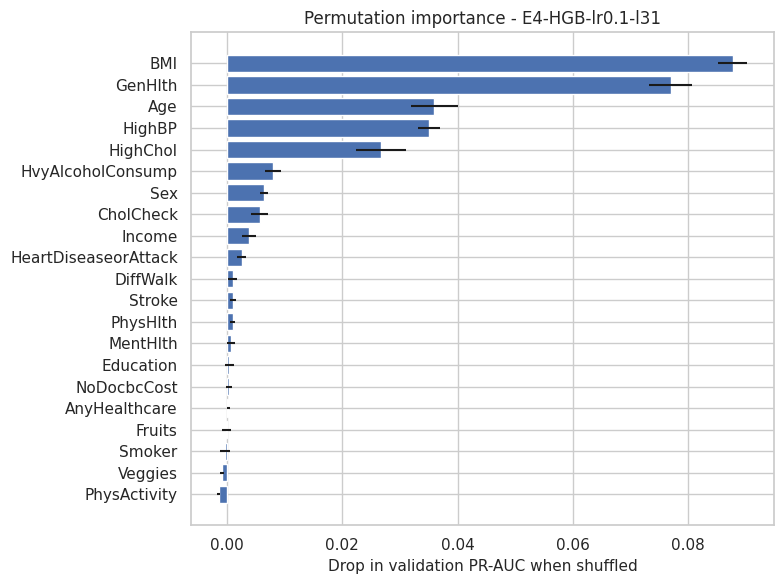

,feature,importance,std
3,BMI,0.0877,0.0026
13,GenHlth,0.0770,0.0037
18,Age,0.0360,0.0041
0,HighBP,0.0350,0.0019
1,HighChol,0.0268,0.0043
10,HvyAlcoholConsump,0.0081,0.0014
17,Sex,0.0064,0.0008
2,CholCheck,0.0057,0.0015
20,Income,0.0038,0.0011
6,HeartDiseaseorAttack,0.0026,0.0008


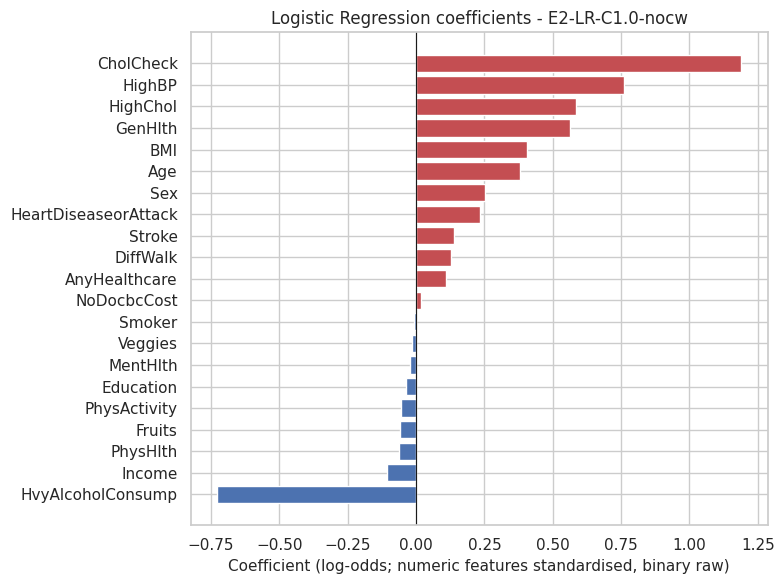

Note: binary coefficients are per 0->1 change; standardised numeric coefficients per 1 SD, so the two groups are not strictly comparable in magnitude.


In [33]:
val_sub = X_val.sample(n=min(20000, len(X_val)), random_state=SEED); y_val_sub = y_val.loc[val_sub.index]
pi = permutation_importance(bt_info["pipe"], val_sub[bt_info["features"]], y_val_sub, scoring="average_precision", n_repeats=5, random_state=SEED, n_jobs=1)
pi_df = pd.DataFrame({"feature": bt_info["features"], "importance": pi.importances_mean, "std": pi.importances_std}).sort_values("importance", ascending=False)
plt.figure(figsize=(8, 6)); plt.barh(pi_df.feature[::-1], pi_df.importance[::-1], xerr=pi_df["std"][::-1], color="#4C72B0")
plt.xlabel("Drop in validation PR-AUC when shuffled"); plt.title(f"Permutation importance - {BEST_TRAD}"); savefig("explain_permutation_importance"); display(pi_df.head(10).round(4))
pi_df.to_csv(RES/"permutation_importance.csv", index=False)

lr_ids = t_val[t_val.family == "LR"].sort_values("pr_auc", ascending=False).exp_id
if len(lr_ids):
    lr_pipe = FITTED[lr_ids.iloc[0]]["pipe"]; names = lr_pipe.named_steps["prep"].get_feature_names_out()
    coef = pd.Series(lr_pipe.named_steps["clf"].coef_[0], index=[n.split("__")[1] for n in names]).sort_values()
    plt.figure(figsize=(8, 6)); plt.barh(coef.index, coef.values, color=np.where(coef.values > 0, "#C44E52", "#4C72B0"))
    plt.axvline(0, color="k", lw=.8); plt.xlabel("Coefficient (log-odds; numeric features standardised, binary raw)"); plt.title(f"Logistic Regression coefficients - {lr_ids.iloc[0]}"); savefig("explain_lr_coefficients")
    print("Note: binary coefficients are per 0->1 change; standardised numeric coefficients per 1 SD, so the two groups are not strictly comparable in magnitude.")

## 18. Limitations, Ethics and Future Work

### Limitations

- **Self-reported data:** The dataset comes from the 2015 Behavioral Risk Factor Surveillance System (BRFSS). Responses may be affected by recall, reporting and non-response bias. The target represents respondents who reported that a health professional had told them they had diabetes; undiagnosed cases may therefore be assigned to class 0.
- **Prediabetes grouped with class 0:** The binary target groups respondents reporting prediabetes with those who do not report diabetes. Class 0 does not necessarily represent people with no metabolic risk.
- **Class imbalance:** Approximately 13.9% of respondents belong to class 1. The majority-class baseline achieved 86.07% accuracy despite zero recall for the positive class, supporting the use of PR-AUC alongside precision, recall and F1-score.
- **Generalisability:** The data represent U.S. adults surveyed in 2015. Results may not transfer to other countries, populations or years without further validation.
- **Duplicate and conflicting records:** The dataset contains exact duplicate rows and identical feature patterns with conflicting labels. These patterns may limit how fully the available features distinguish target classes and may make held-out evaluation somewhat optimistic.
- **Limited clinical information:** The dataset does not include all information relevant to clinical diabetes assessment, such as laboratory measurements of blood glucose or HbA1c. The models rely on the survey indicators available.
- **Association rather than causation:** The analysis identifies patterns associated with reported diabetes status. It cannot establish that a feature caused diabetes or predict when an individual will develop it.

### Ethics and fairness

The error analysis found different false-negative rates across age and income groups. These differences warrant further investigation, especially before considering any health-related application. Real-world use would require more extensive subgroup evaluation, appropriate probability calibration, privacy protections and oversight by relevant health professionals.

The dataset is public and de-identified. No attempt should be made to identify individual respondents. The models developed here are for educational analysis and should not be used to diagnose diabetes or make individual clinical decisions.

### Future work

Further work could include:

- Evaluating the models on additional BRFSS years to assess stability over time.
- Repeating cross-validation or running experiments with different random seeds to quantify performance variability.
- Evaluating probability calibration and selecting thresholds for a clearly defined use case with explicit costs for false negatives and false positives.
- Comparing class weighting with resampling methods under the same evaluation protocol.
- Examining subgroup performance in greater detail.
- Testing additional models and explainability methods where they add meaningful value.

These steps would help establish the stability of the results and whether the models generalise beyond this dataset.

In [34]:
t_all = tracker.table(); tt = t_all[t_all.eval_split == "test"]
t_val = t_all[t_all.eval_split == "validation"].drop_duplicates("exp_id", keep="last")   # one row per exp_id so .loc returns a scalar
tq = lambda key, tag: tt[tt.exp_id == f"E10-{key}-{tag}"].iloc[0]
a, b = tq(BEST_TRAD, "thr=val-tuned"), tq(BEST_DL, "thr=val-tuned"); d0 = tq("Dummy", "thr=0.50")
display(Markdown(f'''
## 19. Conclusion (numbers below are generated from the executed runs)

**Dataset.** {N_RAW_ROWS:,} raw survey rows, {len(FEATURES)} features; target definition: {TARGET_DEFINITION}; positive prevalence {df_raw[TARGET].mean():.1%}. Stratified 70/15/15 split (seed {SEED}).

**RQ1 - best traditional model.** `{BEST_TRAD}` (validation PR-AUC {t_val.set_index('exp_id').loc[BEST_TRAD,'pr_auc']:.4f}). On the untouched test set at the validation-selected threshold {THR[BEST_TRAD]:.2f}: PR-AUC {a.pr_auc:.4f}, ROC-AUC {a.roc_auc:.4f}, recall {a.recall:.3f}, precision {a.precision:.3f}, F1 {a.f1:.3f}, accuracy {a.accuracy:.3f}.

**RQ2 - neural network.** `{BEST_DL}` (validation PR-AUC {t_val.set_index('exp_id').loc[BEST_DL,'pr_auc']:.4f}); test PR-AUC {b.pr_auc:.4f}, ROC-AUC {b.roc_auc:.4f}, recall {b.recall:.3f}, precision {b.precision:.3f}, F1 {b.f1:.3f}. Difference in test PR-AUC (NN - traditional): {b.pr_auc-a.pr_auc:+.4f}.

**Baseline.** Majority class: test accuracy {d0.accuracy:.3f} with recall {d0.recall:.1f}, which shows accuracy alone is uninformative.

**RQ3-RQ5.** See Sections 8-10 (effect of class weights, tuning and feature selection, via the observation column), Section 16 (error patterns) and Section 18 (limitations). *Write the final synthesis in your own words, citing the specific rows/figures.*

This remains an association study of self-reported survey data, not a diagnostic system.
'''))


## 19. Conclusion (numbers below are generated from the executed runs)

**Dataset.** 253,680 raw survey rows, 21 features; target definition: 1 = respondent reported diabetes (Diabetes_012 == 2); 0 = no diabetes OR prediabetes (Diabetes_012 in {0,1}); positive prevalence 13.9%. Stratified 70/15/15 split (seed 42).

**RQ1 - best traditional model.** `E4-HGB-lr0.1-l31` (validation PR-AUC 0.4266). On the untouched test set at the validation-selected threshold 0.27: PR-AUC 0.4270, ROC-AUC 0.8293, recall 0.533, precision 0.406, F1 0.461, accuracy 0.826.

**RQ2 - neural network.** `DL-E3-reg` (validation PR-AUC 0.4297); test PR-AUC 0.4275, ROC-AUC 0.8299, recall 0.617, precision 0.381, F1 0.471. Difference in test PR-AUC (NN - traditional): +0.0005.

**Baseline.** Majority class: test accuracy 0.861 with recall 0.0, which shows accuracy alone is uninformative.

**RQ3-RQ5.** See Sections 8-10 (effect of class weights, tuning and feature selection, via the observation column), Section 16 (error patterns) and Section 18 (limitations). *Write the final synthesis in your own words, citing the specific rows/figures.*

This remains an association study of self-reported survey data, not a diagnostic system.


## 20. Save Deliverables

The final outputs are saved so the experiments can be reviewed and reproduced. They include the selected traditional-model pipeline, the neural network and its fitted preprocessor, experiment results, final test metrics, test predictions, configuration details, environment information, figures and experiment logs.

The traditional pipeline includes its preprocessing steps. The neural network is saved separately from its fitted preprocessor, so both components are required when preparing new data for prediction.

Results are saved in CSV and JSON formats, and the figures and logs are included in the output archive.

In [35]:
joblib.dump(FITTED[BEST_TRAD]["pipe"], MODELS/"best_traditional_pipeline.joblib")
NN_MODELS[BEST_DL].save(MODELS/"best_neural_network.keras"); joblib.dump(prep_nn, MODELS/"nn_preprocessor.joblib")
full = tracker.table(); full.to_csv(RES/"experiment_results_all.csv", index=False)
TEST_TBL.to_csv(RES/"final_test_metrics.csv", index=False); json.dump(TEST_TBL.to_dict("records"), open(RES/"final_test_metrics.json", "w"), indent=2, default=str)
json.dump(ENV, open(RES/"environment.json", "w"), indent=2)
json.dump({**FINAL_CONFIG, "seed": SEED, "split": SPLIT_DESC, "target": TARGET, "target_definition": TARGET_DEFINITION, "features": FEATURES,
           "selected_traditional_features": FITTED[BEST_TRAD]["features"], "raw_rows": N_RAW_ROWS, "data_file": DATA_PATH.name,
           "debug_subsample": DEBUG_SUBSAMPLE, "tune_subsample": TUNE_SUBSAMPLE, "n_search_iter": N_SEARCH_ITER}, open(RES/"run_configuration.json", "w"), indent=2, default=str)
pd.DataFrame({"y_true": y_test.values, **{f"proba_{LABELS[k].split(' (')[0].replace(' ', '_').lower()}": v for k, v in TEST_PROBA.items()}}, index=y_test.index).to_csv(RES/"test_predictions.csv")

readme = f'''# Diabetes health indicators - ML vs DL
Notebook outputs. Best traditional model: {BEST_TRAD}; best neural net: {BEST_DL}. Seed {SEED}.
Load: `joblib.load("models/best_traditional_pipeline.joblib").predict_proba(df[features])` (features in results/run_configuration.json).
Neural net: standardise with `models/nn_preprocessor.joblib`, then `keras.saving.load_model("models/best_neural_network.keras")`.
Association study on self-reported survey data - not a diagnostic tool. Raw data are NOT included; see the notebook for the Kaggle source.
'''
(OUT/"README_outputs.md").write_text(readme)

import shutil; shutil.make_archive("diabetes_outputs", "zip", OUT)
print("Saved files:"); [print(" ", p.relative_to(OUT)) for p in sorted(OUT.rglob("*")) if p.is_file() and "wandb" not in str(p)]
print("Archive: diabetes_outputs.zip")
try:
    from google.colab import files; files.download("diabetes_outputs.zip")
except ImportError: pass

Saved files:
  README_outputs.md
  figures/dl_learning_curves_all_runs.png
  figures/eda_boxplots_by_class.png
  figures/eda_correlation_heatmap.png
  figures/eda_feature_distributions.png
  figures/eda_rate_by_binary.png
  figures/eda_rate_by_ordinal.png
  figures/eda_target_distribution.png
  figures/explain_lr_coefficients.png
  figures/explain_permutation_importance.png
  figures/featsel_mutual_information.png
  figures/final_confusion_matrices.png
  figures/final_roc_pr_curves.png
  figures/learning_curves_best_models.png
  figures/results_validation_pr_auc_all_experiments.png
  logs/experiment_log.jsonl
  models/best_neural_network.keras
  models/best_traditional_pipeline.joblib
  models/nn_preprocessor.joblib
  results/environment.json
  results/experiment_results_all.csv
  results/experiment_results_validation.csv
  results/final_test_metrics.csv
  results/final_test_metrics.json
  results/nn_training_histories.json
  results/permutation_importance.csv
  results/run_configurati

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
t_all = tracker.table(); n_val = int(((t_all.eval_split == "validation")).sum())
chk = {
 "Raw rows >= 20,000 verified programmatically": N_RAW_ROWS >= MIN_RAW_ROWS,
 "Target validated and defined empirically": TARGET in df_raw.columns and "unverified" not in TARGET_DEFINITION,
 "Full (not balanced) dataset used; not in DEBUG mode": "5050" not in DATA_PATH.name and not DEBUG_SUBSAMPLE,
 "Stratified, seeded train/val/test split": True,
 "Preprocessing fitted inside pipelines on training data only": True,
 ">= 3 traditional algorithm families + dummy baseline": t_all[t_all.paradigm == "Traditional ML"].family.nunique() >= 4,
 "Traditional hyper-parameter search (E5) recorded": t_all.exp_id.str.startswith("E5").any(),
 "Feature-selection experiment (E9) recorded": t_all.exp_id.str.startswith("E9").any(),
 "Keras model built on tf.data with EarlyStopping(restore_best_weights)": len(NN_MODELS) > 0,
 ">= 7 experiments executed (count: %d)" % n_val: n_val >= 7,
 "W&B offline run folders exist (or JSONL fallback)": len(list((LOGS/'wandb').glob('offline-run-*'))) > 0 or (LOGS/'experiment_log.jsonl').exists(),
 "Test set evaluated once, after freezing selection": any(t_all.eval_split == "test"),
 "Confusion matrices / ROC / PR / learning curves saved": all((FIG/f).exists() for f in ["final_confusion_matrices.png", "final_roc_pr_curves.png", "learning_curves_best_models.png"]),
 "Best traditional model saved (.joblib)": (MODELS/"best_traditional_pipeline.joblib").exists(),
 "Best neural network saved (.keras)": (MODELS/"best_neural_network.keras").exists(),
 "Results CSV / metrics JSON / config saved": all((RES/f).exists() for f in ["experiment_results_all.csv", "final_test_metrics.json", "run_configuration.json"]),
}
for k, v in chk.items(): print(("[x] " if v else "[ ] ") + k)
print("\nDONE")

[x] Raw rows >= 20,000 verified programmatically
[x] Target validated and defined empirically
[x] Full (not balanced) dataset used; not in DEBUG mode
[x] Stratified, seeded train/val/test split
[x] Preprocessing fitted inside pipelines on training data only
[x] >= 3 traditional algorithm families + dummy baseline
[x] Traditional hyper-parameter search (E5) recorded
[x] Feature-selection experiment (E9) recorded
[x] Keras model built on tf.data with EarlyStopping(restore_best_weights)
[x] >= 7 experiments executed (count: 25)
[x] W&B offline run folders exist (or JSONL fallback)
[x] Test set evaluated once, after freezing selection
[x] Confusion matrices / ROC / PR / learning curves saved
[x] Best traditional model saved (.joblib)
[x] Best neural network saved (.keras)
[x] Results CSV / metrics JSON / config saved

DONE
